# T2 The detector response: what the network will see: reference solution

Questions T2.1, T2.2, T2.3, T2.4, T2.5 of [TASKS.md](../../TASKS.md). The code is in the scripts named below (run from the repository root); this notebook runs them, shows their figures and gives the answers. Every number quoted comes from `results/`.

In [1]:
import os
from pathlib import Path

import IPython.display as ipd

here = Path.cwd()
os.chdir(next(p for p in (here, *here.parents) if (p / "pyproject.toml").exists()))  # the repository root
FIGURES = Path("solutions/stage1_flash/figures")


def show(*names):
    """Display the figures of a question (GIF animates, else the PNG)."""
    for name in names:
        path = next(p for p in (FIGURES / f"{name}.gif", FIGURES / f"{name}.png") if p.exists())
        ipd.display(ipd.Image(filename=str(path), width=900))


## Run the scripts

Data sets are generated on first use and cached in `solutions/stage1_flash/data/`.

In [2]:
!python solutions/stage1_flash/task2_response.py
!python solutions/stage1_flash/task2_proposals.py

T2.1: empty sensors 0.697 %; mean hit sensors 31.777; all 32 hit in 88.4 % of the events
T2.2: collection 0.2615 (centre) -> 0.4006 (wall), disc average 0.3254; Q at 2 MeV 523.3 -> 806.2 p.e.
T2.3: mean time since t0 6.88 ns; relative-time spread 3.138 ns; t0-shift test max diff 3.81e-06 ns
T2.4: input [200000, 64], charge half 2.7822 +- 0.9933, time half 2.5253 +- 3.1339 ns
results -> ./solutions/stage1_flash/results/T2.json


1. charge at d = 0.1 / 1.0 m: {'0.02m': 860.6, '0.1m': 217.5, '0.3m': 66.86, '1m': 14.17, '1.9m': 4.95}
2. first-hit slope 5.979 ns/m (expected 5), intercept -2.468 ns
3. barycentre error 3.3 cm (centre) -> 21.17 cm (wall)
4. naive energy bias -19.96 % (centre) -> 22.0 % (wall); spread 14.13 % (all), 4.53 % with f(r)
5. correlations: same theta: (0, 0) m, 2 MeV: nn -0.0004, same theta: (0.7, 0) m, 2 MeV: nn -0.0004, 2 MeV, vertices r < 0.2 m: nn 0.3327, 2 MeV, vertices 0.6 <= r < 0.8 m: nn 0.8528, prior energies, vertices r < 0.2 m: nn 0.8548
6. fates (disc): detected 0.3254, bulk 0.5173, wall 0.1573
7. composition centre [0.607807, 0.296586, 0.095607], disc [0.693001, 0.211347, 0.095652]
8. r >= 0.95 m: collection 0.5239 facing a sensor, 0.2737 facing a gap
9. Q = 800: E std 0.3617 MeV
10. PCA: first 3 components 0.789, corr(PC1, log E) 0.9604
results -> ./solutions/stage1_flash/results/T2.json


## T2.1 Sensor charges, hit sensors, empty sensors

A sensor typically sees 14 p.e. (median; mean 28.0), with a long tail up to 2599 p.e. from vertices near the wall.
Almost every sensor is hit: 88.4 % of the events have all 32 sensors hit. Empty sensors (0.70 % overall) follow the
Poisson law P(n_j = 0) = exp(−μ_j): their fraction falls exponentially with E and rises toward the wall, where the far
side of the ring sees little light.

**Details**

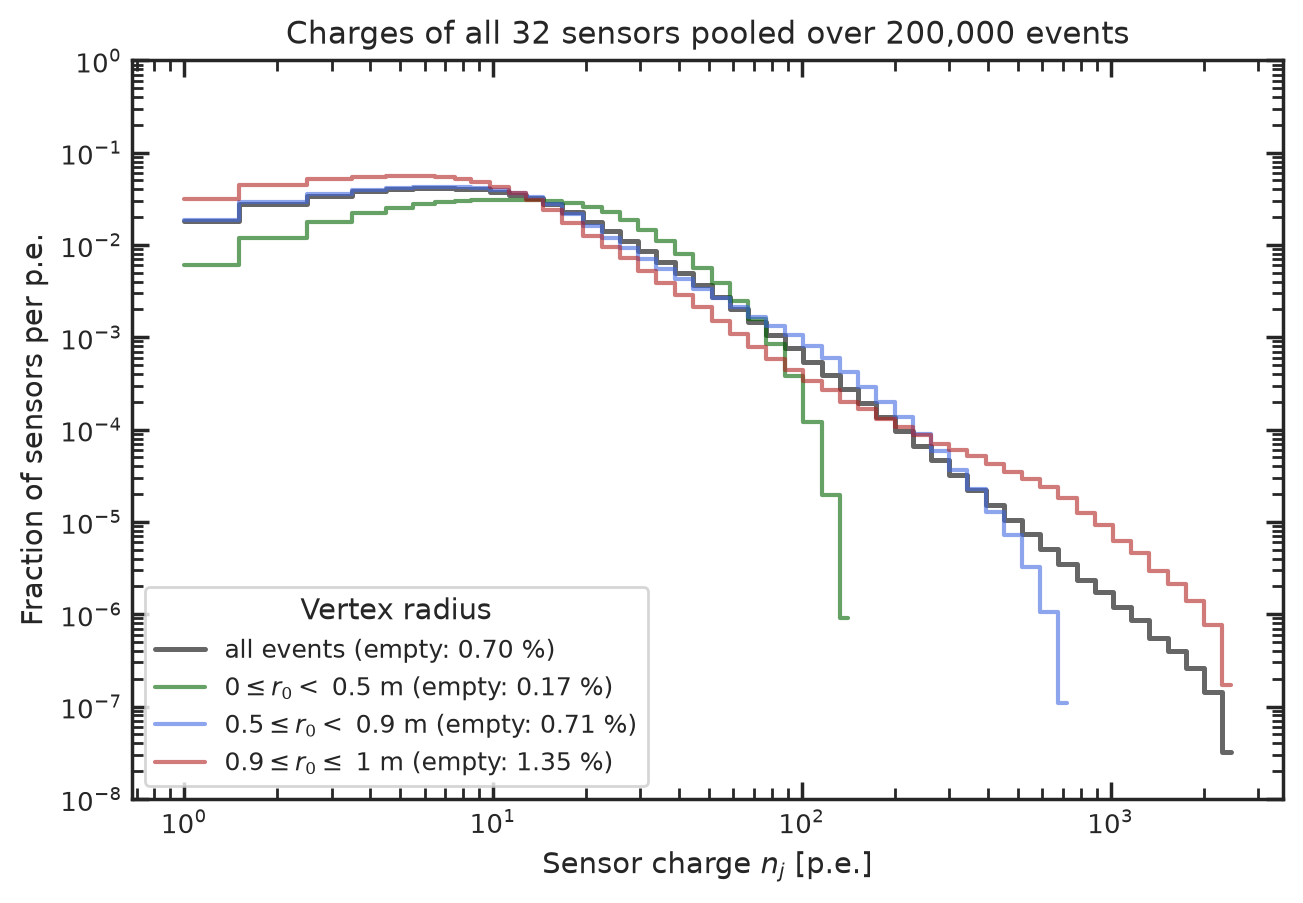

In [3]:
show("t2_1_sensor_charges")

- *Pooled charges:* median 14, mean 28.0, 99th percentile 234 p.e.; the tail above 145 p.e. comes only from r > 0.5 m,
  where one sensor can catch most of the light.

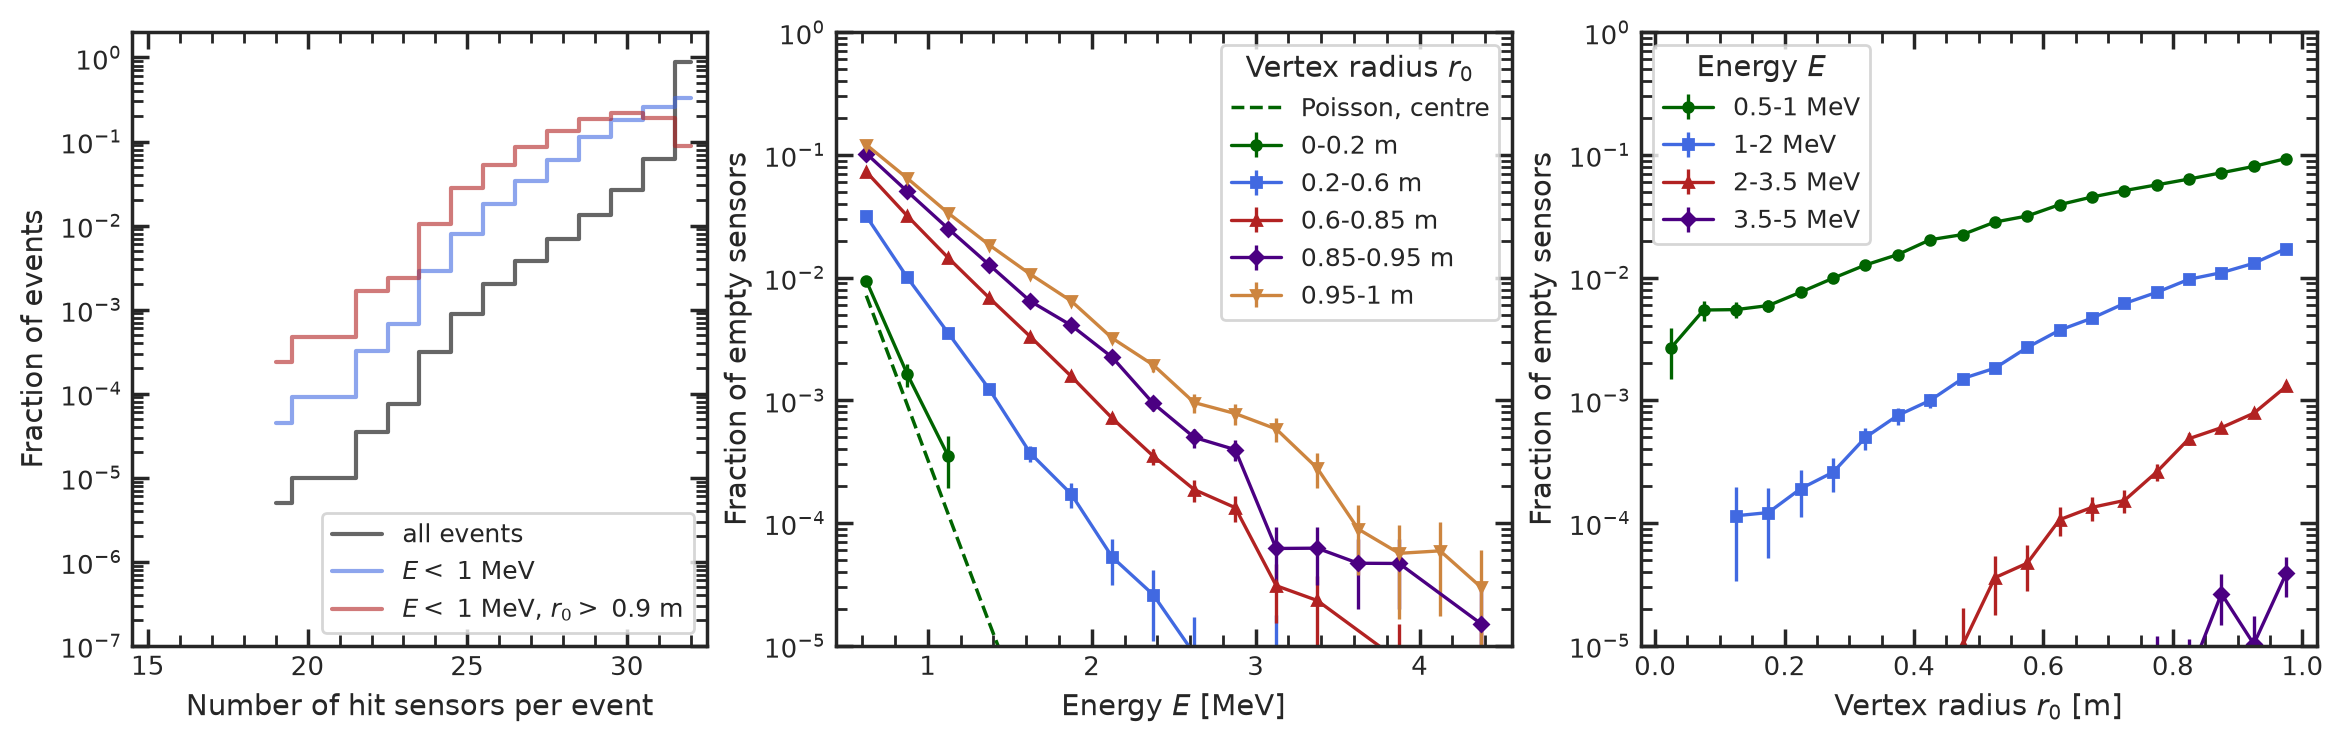

In [4]:
show("t2_1_hit_and_empty_sensors")

- *Hit multiplicity:* mean 31.78 of 32 sensors, minimum 19; only (8.8 ± 0.4) % of the 4244 events with E < 1 MeV and
  r > 0.9 m have all sensors hit.
- *Empty sensors vs E and r:* 1.45 % for E < 1 MeV and r < 0.5 m, 9.3 % for E < 1 MeV and r > 0.95 m, 0.004 % for
  E > 3.5 MeV and r > 0.95 m.
- *Check:* for r < 0.2 m the fraction is close to the Poisson expectation for a vertex at the centre,
  exp(−Y E f_c / M) with f_c = 0.2615: 0.94 % measured vs 0.71 % expected in the lowest energy bin, the excess coming
  from vertices up to 0.2 m off-centre.

*Figures:* `t2_1_sensor_charges`, `t2_1_hit_and_empty_sensors` (200 000 prior events, `task2_response.py`).
*Numbers:* `results/T2.json` under `T2.1`.

## T2.2 Total charge and light collection

Q grows linearly with E, but at a given E it spreads over a band, because the light collection Q/(YE) depends on the
vertex: 0.261 at the centre, 0.401 in the last radius bin (a factor 1.53), disc average 0.325. The reason is the path
length, not the solid angle: from a vertex near the wall about half of the photons reach the nearby wall after a short
way and are not absorbed or scattered in the bulk (λa = 1.5 m, λs = 2 m).

**Details**

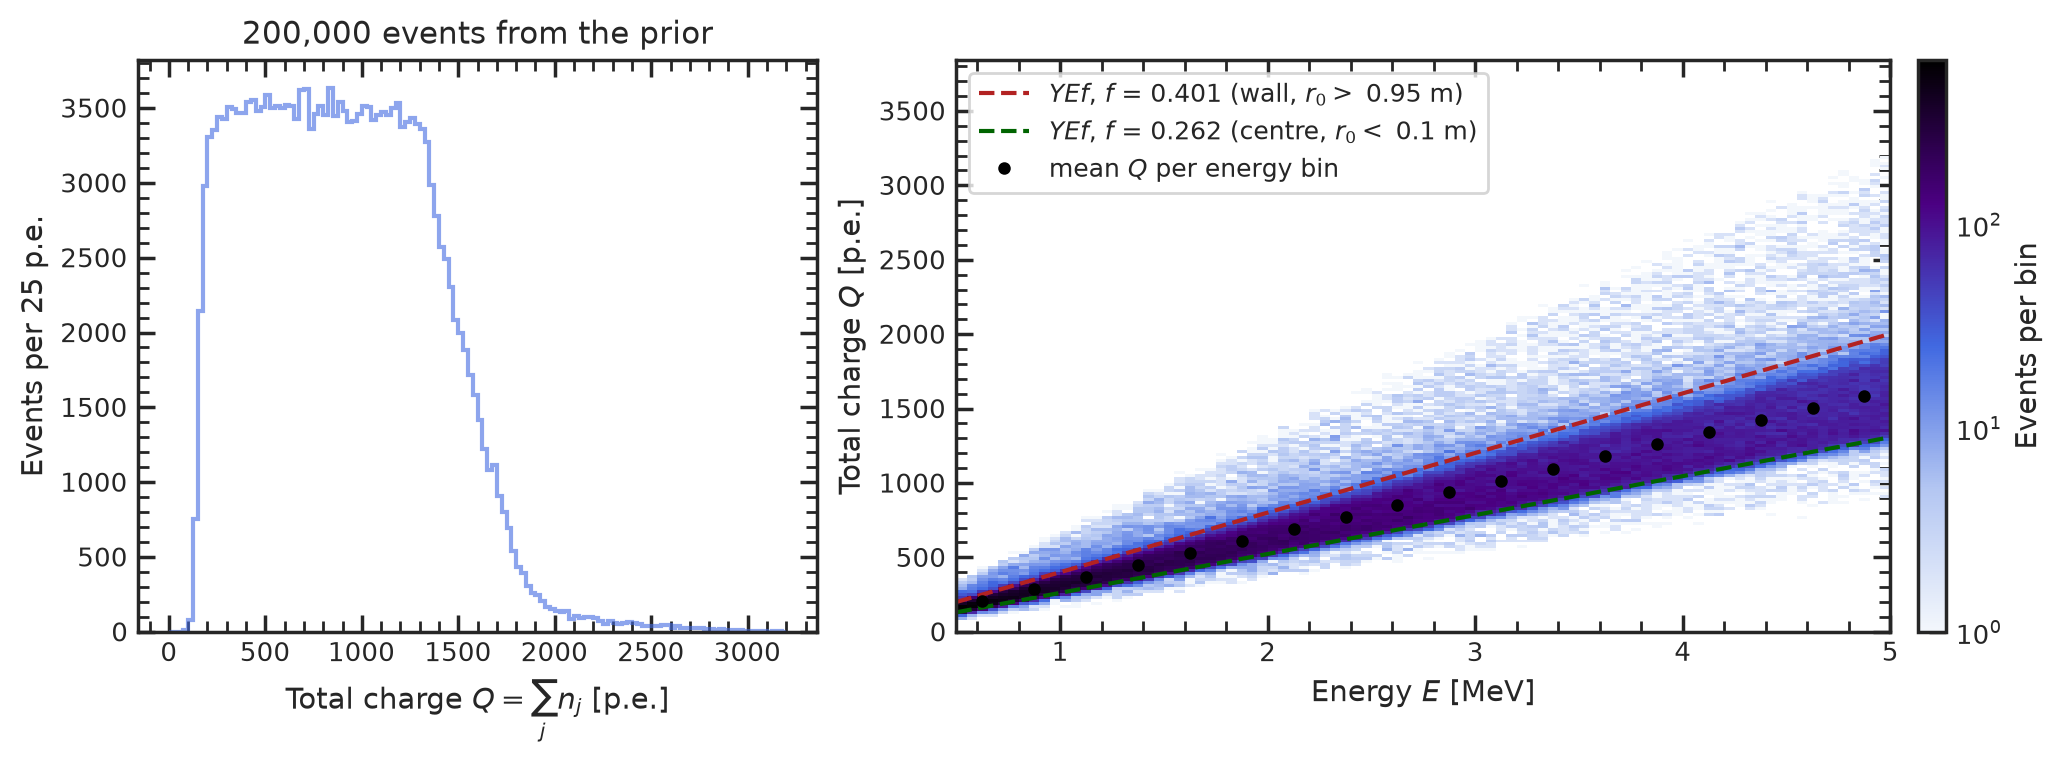

In [5]:
show("t2_2_total_charge")

- *Q distribution:* 90 to 3191 p.e. (1-99 %: 165-2018 p.e., median 873); the flat energy prior makes the plateau, the
  position dependence of the collection the soft edges and the high tail.
- *Band at fixed E:* at E = 2.00 ± 0.05 MeV the spread of Q is 112 p.e., while photon statistics alone would give
  25.5 p.e.; at E = 2 MeV with r < 0.1 m the spread is purely Poisson (22.6 vs 22.9 p.e.). At 2 MeV the collection is
  523 p.e. at the centre and 806 p.e. at the wall.

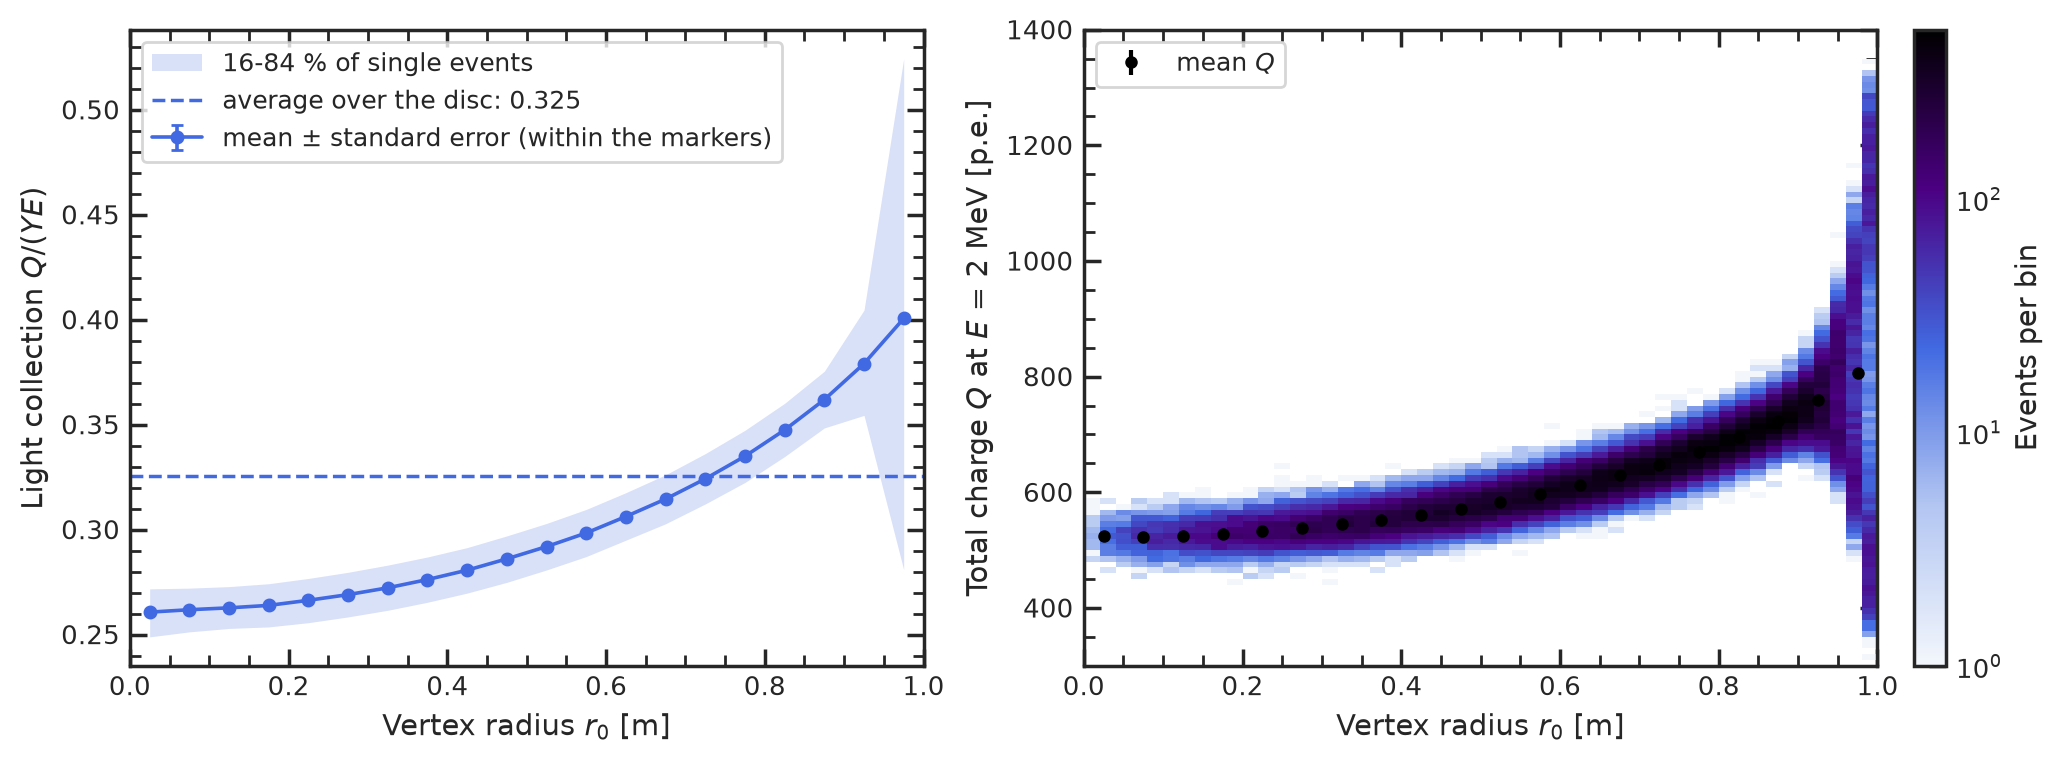

In [6]:
show("t2_2_light_collection")

- *Collection vs r:* standard errors below 0.001 (error bars smaller than the markers). The single-event band widens
  sharply in the last bin (16-84 %: 0.28-0.52) because there the collection depends on whether the vertex faces a
  sensor or a gap (T2.5, item 8).
- *Why not the solid angle:* averaged over the azimuth, the angle under which all sensors together are seen is the
  photocoverage at every radius (what the near sensors gain, the far ones lose); without absorption and scattering the
  collection does not rise at all (T3.1: straight light stays at 0.509 from the centre to the wall; T3.3 splits the
  rise into its parts).

*Figures:* `t2_2_total_charge`, `t2_2_light_collection` (200 000 prior events; 100 000 events at E = 2 MeV).
*Numbers:* `results/T2.json` under `T2.2`.

## T2.3 Mean, first and relative times

Every recorded time contains the unknown t0 ~ U(0, 10 ns), which is as large as the whole time-of-flight range
(d_j / c_n = 0-10 ns), so absolute times would mostly measure t0. The relative times τ_j − τ̄, with τ̄ the
charge-weighted mean over the hit sensors, remove t0 exactly and keep the pattern: near sensors early, far sensors
late.

**Details**

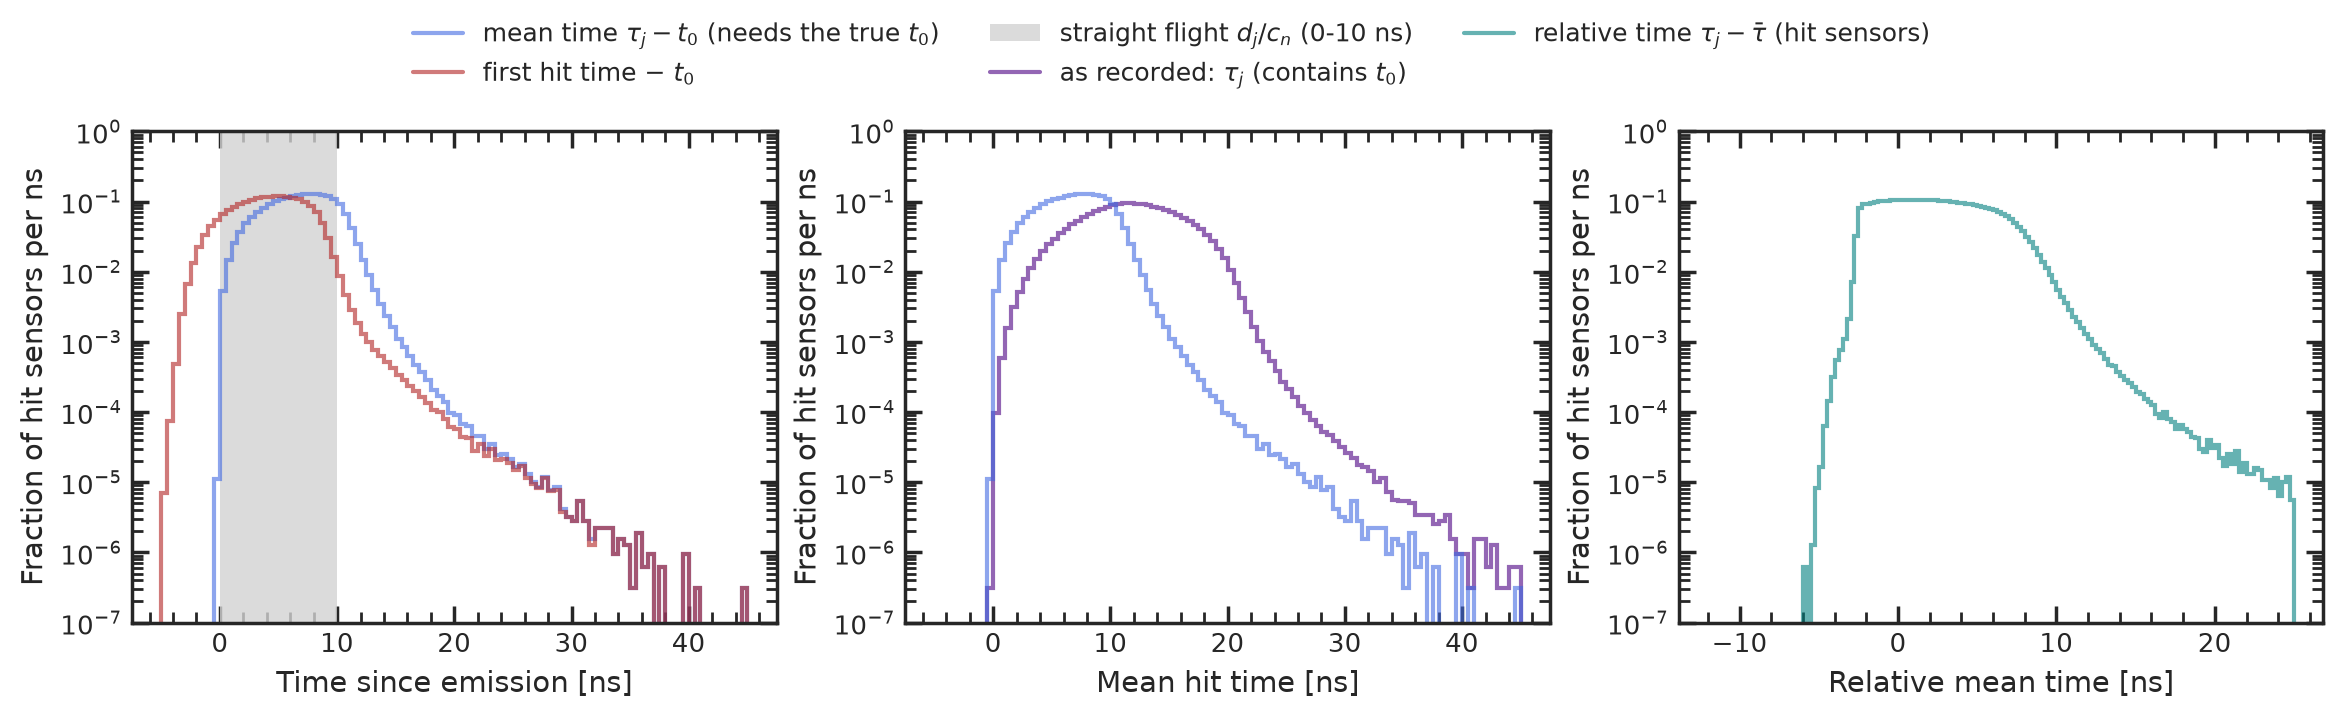

In [7]:
show("t2_3_times")

- *Mean times from the emission:* τ_j − t0 has median 7.0 ns (1-99 %: 1.0-12.8 ns) with a tail of scattered and
  reflected light beyond 20 ns (13.3 % are later than 10 ns).
- *First times:* earlier (median 4.3 ns); 8.9 % even precede t0, because the earliest of many photons picks the early
  tail of the 1 ns jitter.
- *Effect of t0:* the spread of the mean times grows from 2.80 ns (τ_j − t0) to 4.01 ns as recorded.

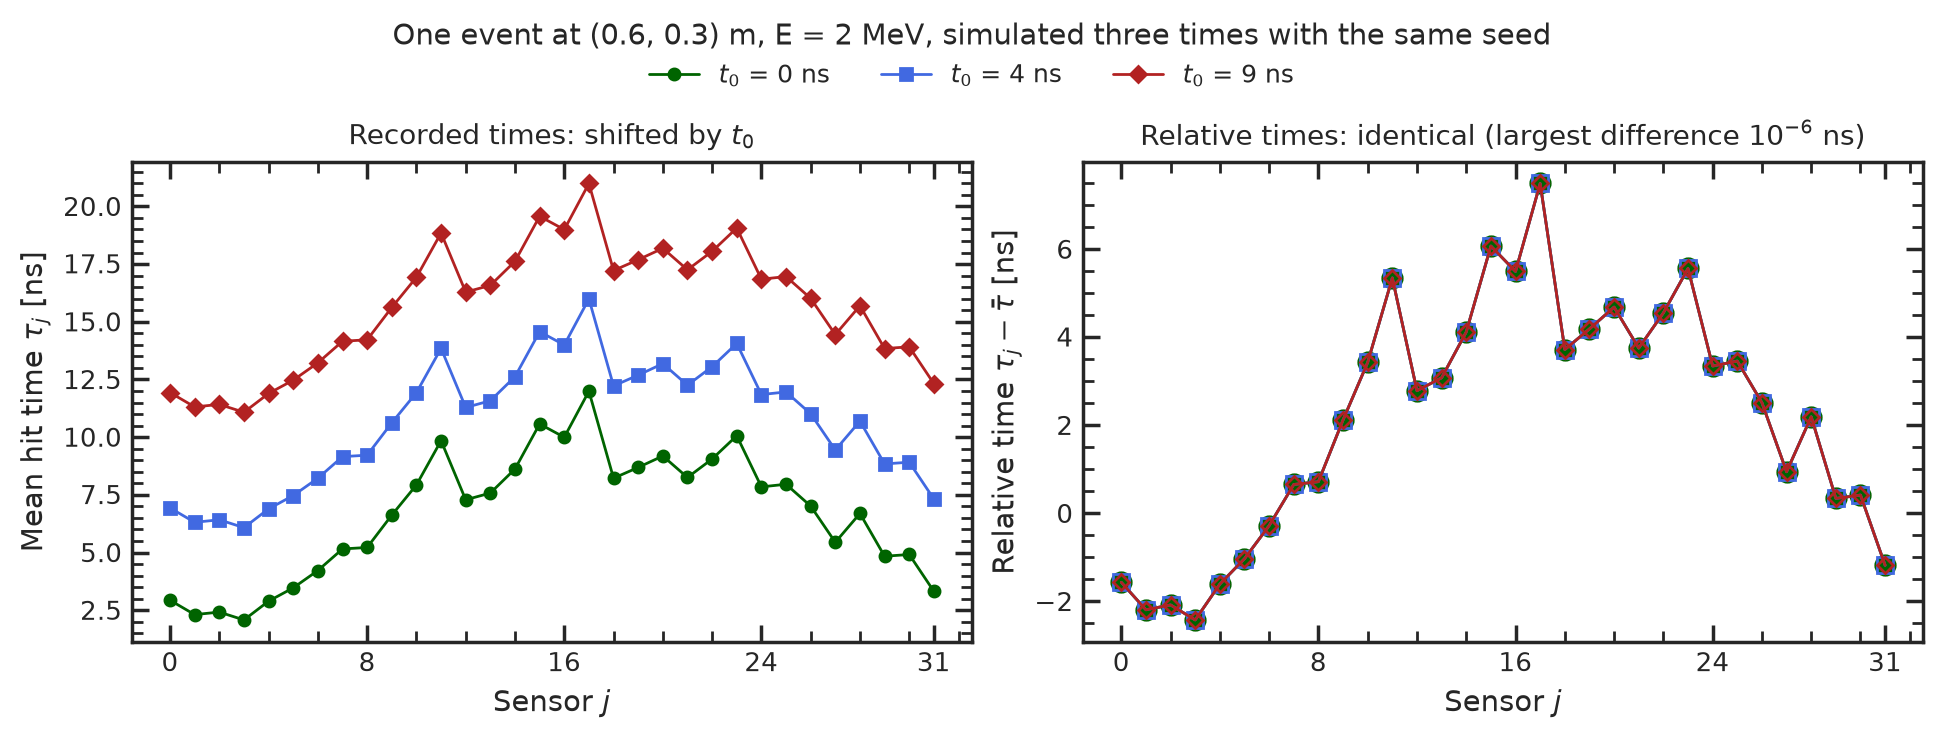

In [8]:
show("t2_3_relative_times")

- *Check of the cancellation:* the same event simulated with the same seed at t0 = 0, 4 and 9 ns gives relative times
  that agree to 9.5 × 10⁻⁷ ns (float32 rounding); shifting t0 by 7.5 ns for 2000 events changes the network input by at
  most 3.8 × 10⁻⁶ ns. Only the common offset of each event is lost (dominated by t0 anyway); the pattern (spread
  3.14 ns) stays.

*Figures:* `t2_3_times`, `t2_3_relative_times` (`task2_response.py`). *Numbers:* `results/T2.json` under `T2.3`.

## T2.4 The network input

`network_input(charge, time_mean)` returns a float32 array of shape [N, 64]: the charge half log(1 + n_j) and the time
half τ_j − τ̄ in ns. The two halves have different units and scales, so each of the 64 inputs should be standardised
before training. An empty sensor is the point (0, 0): unambiguous in the charge half, ambiguous in the time half.

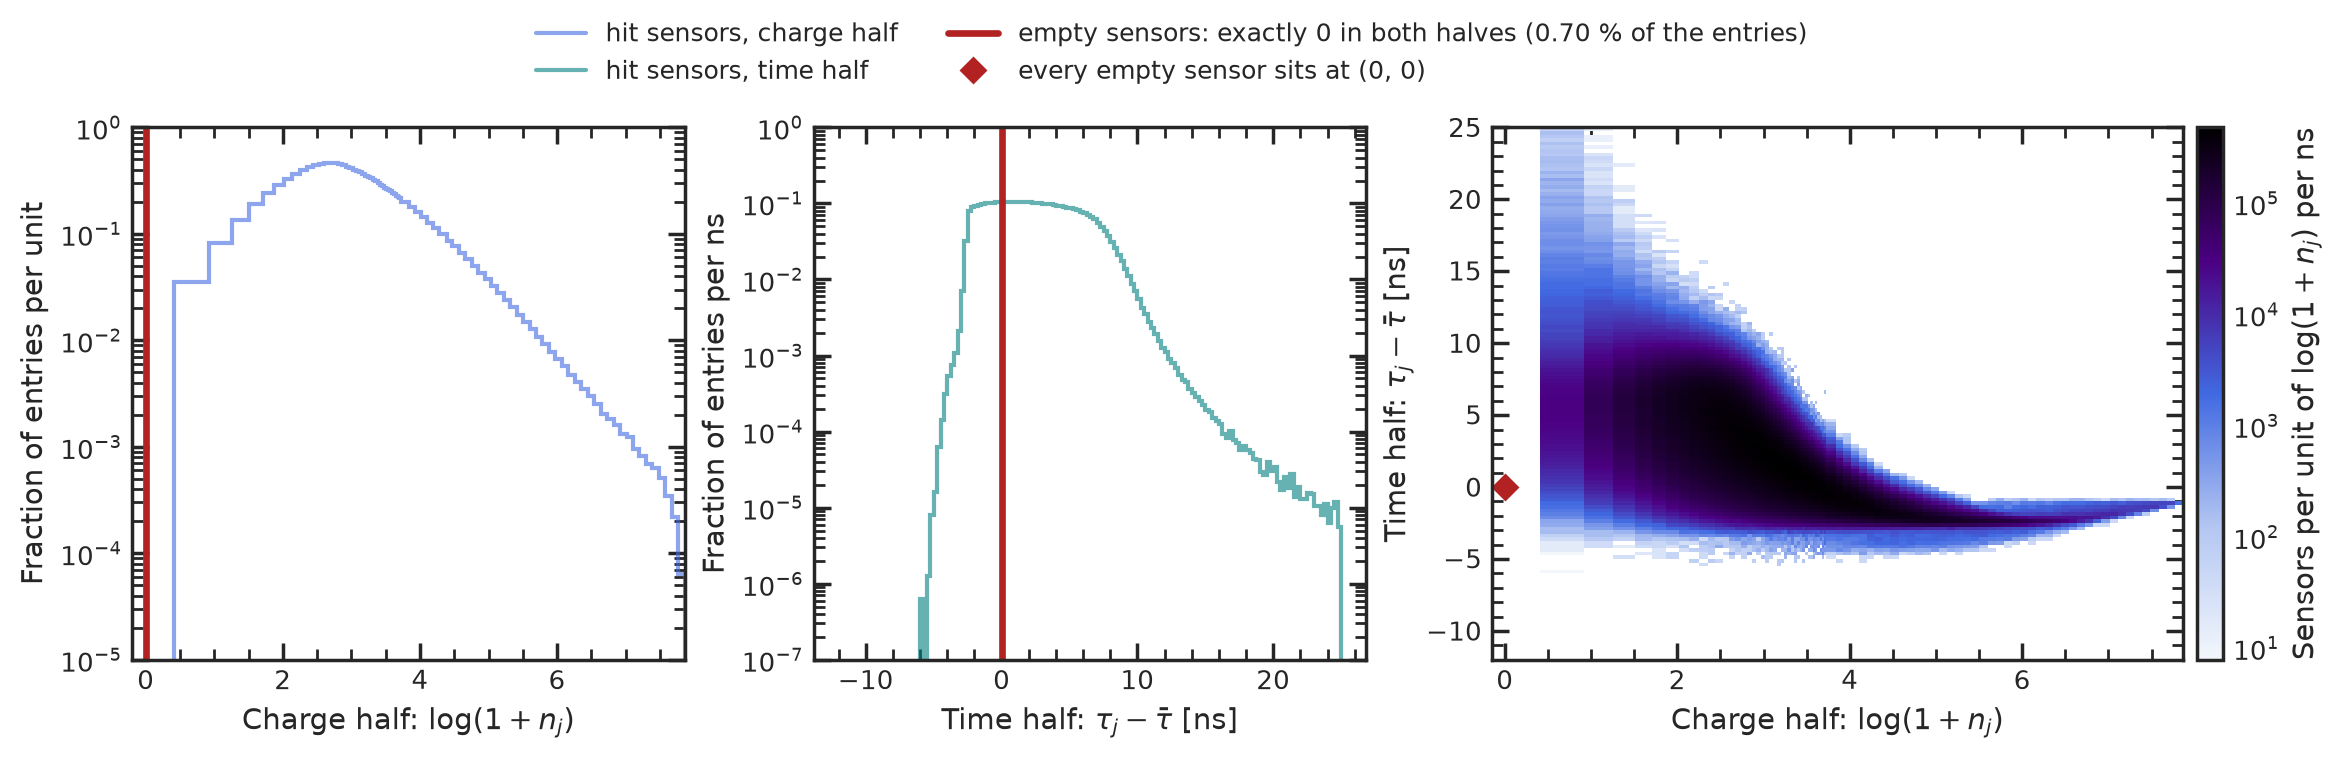

In [9]:
show("t2_4_network_input")

**Details**

- *Scales:* charge half mean 2.78, standard deviation 0.99, maximum 7.86; time half mean 2.53 ns, standard deviation
  3.13 ns, 1-99 %: −2.5 to 9.7 ns.
- *Physics in the joint distribution:* bright (near) sensors are early and dim (far) sensors late (correlation −0.67
  on hit sensors); this is also why the plain mean of the time half is positive (2.53 ns) while its charge-weighted
  mean is zero by construction (largest deviation 1.1 × 10⁻⁷ ns).
- *Empty sensors* (0.70 % of all entries): log(1 + 0) = 0, and the time is set to 0 by convention. A hit sensor has at
  least log 2 = 0.69 in the charge half, but in the time half a 0 looks exactly like a sensor firing at the mean time,
  so the network has to learn from the charge half that the time is missing. No event of this sample has a single hit
  sensor, so every exact zero in the time half belongs to an empty sensor.

*Figure:* `t2_4_network_input` (200 000 prior events, `task2_response.py`). *Numbers:* `results/T2.json` under
`T2.4`.

## T2.5 Own proposals

Ten proposals, seven from the task sheet and three of our own. The common thread: the total charge alone mixes E and the vertex, the charge pattern and the times carry the rest. Every item is a figure of its own.

**Menu**

1. Charge versus vertex-sensor distance d_j - `t2_5_charge_vs_distance`
2. First-hit time versus d_j and the slope 1/c_n - `t2_5_first_hit_time`
3. Charge-weighted barycentre versus the true vertex - `t2_5_barycentre`
4. Naive energy from Q with one calibration constant - `t2_5_naive_energy`
5. Sensor-sensor charge correlations - `t2_5_correlations`
6. Photon fates versus r - `t2_5_photon_fates`
7. Direct / scattered / reflected composition versus r - `t2_5_composition`
8. Own: azimuthal modulation near the wall, vertex facing a sensor or a gap - `t2_5_azimuthal_modulation`
9. Own: the E-r degeneracy of Q at fixed Q, and how the charge pattern breaks it - `t2_5_energy_radius_degeneracy`
10. Own: principal components of the log charges - `t2_5_pca_network_input`

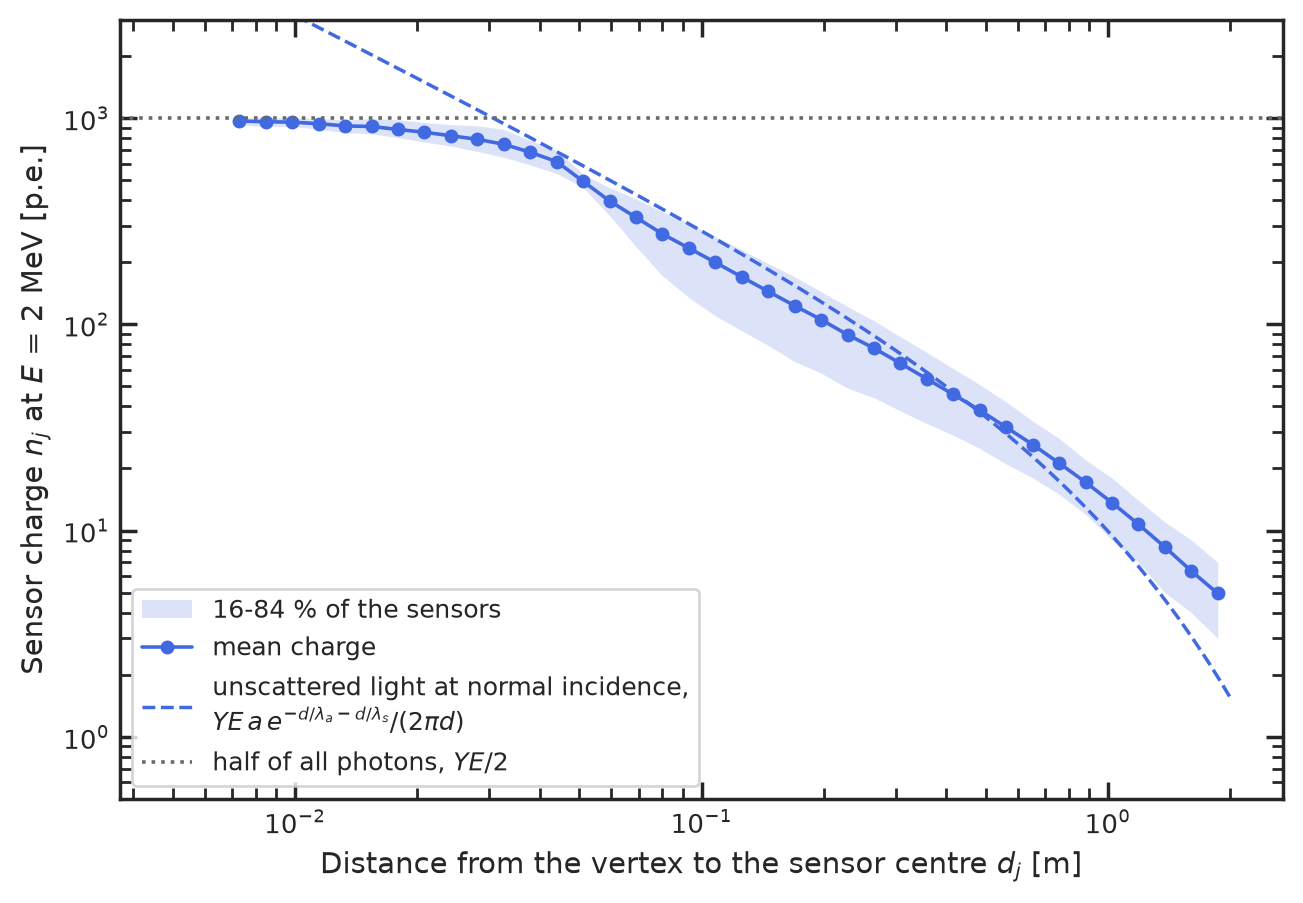

In [10]:
show("t2_5_charge_vs_distance")

### 1. Charge versus distance

At E = 2 MeV the mean sensor charge falls from 993 p.e. for a vertex touching a sensor
(half of all photons, Y E / 2 = 1000) to 14.2 p.e. at d = 1 m and 5.0 p.e. at 1.9 m. Between about 5 cm and 0.5 m it
runs parallel to the 2-D law ∝ exp(-d/λ)/d (an arc subtends an angle ∝ 1/d in two dimensions, not a solid angle
∝ 1/d²), but below the curve of unscattered light at normal incidence (0.1 m: 218 versus 283 p.e.), because most
sensors are seen at an angle; at large distances it lies above it, where scattered and reflected light dominate
(1.9 m: 5.0 versus 1.8 p.e.). The wide band shows that the distance alone does not fix the charge.

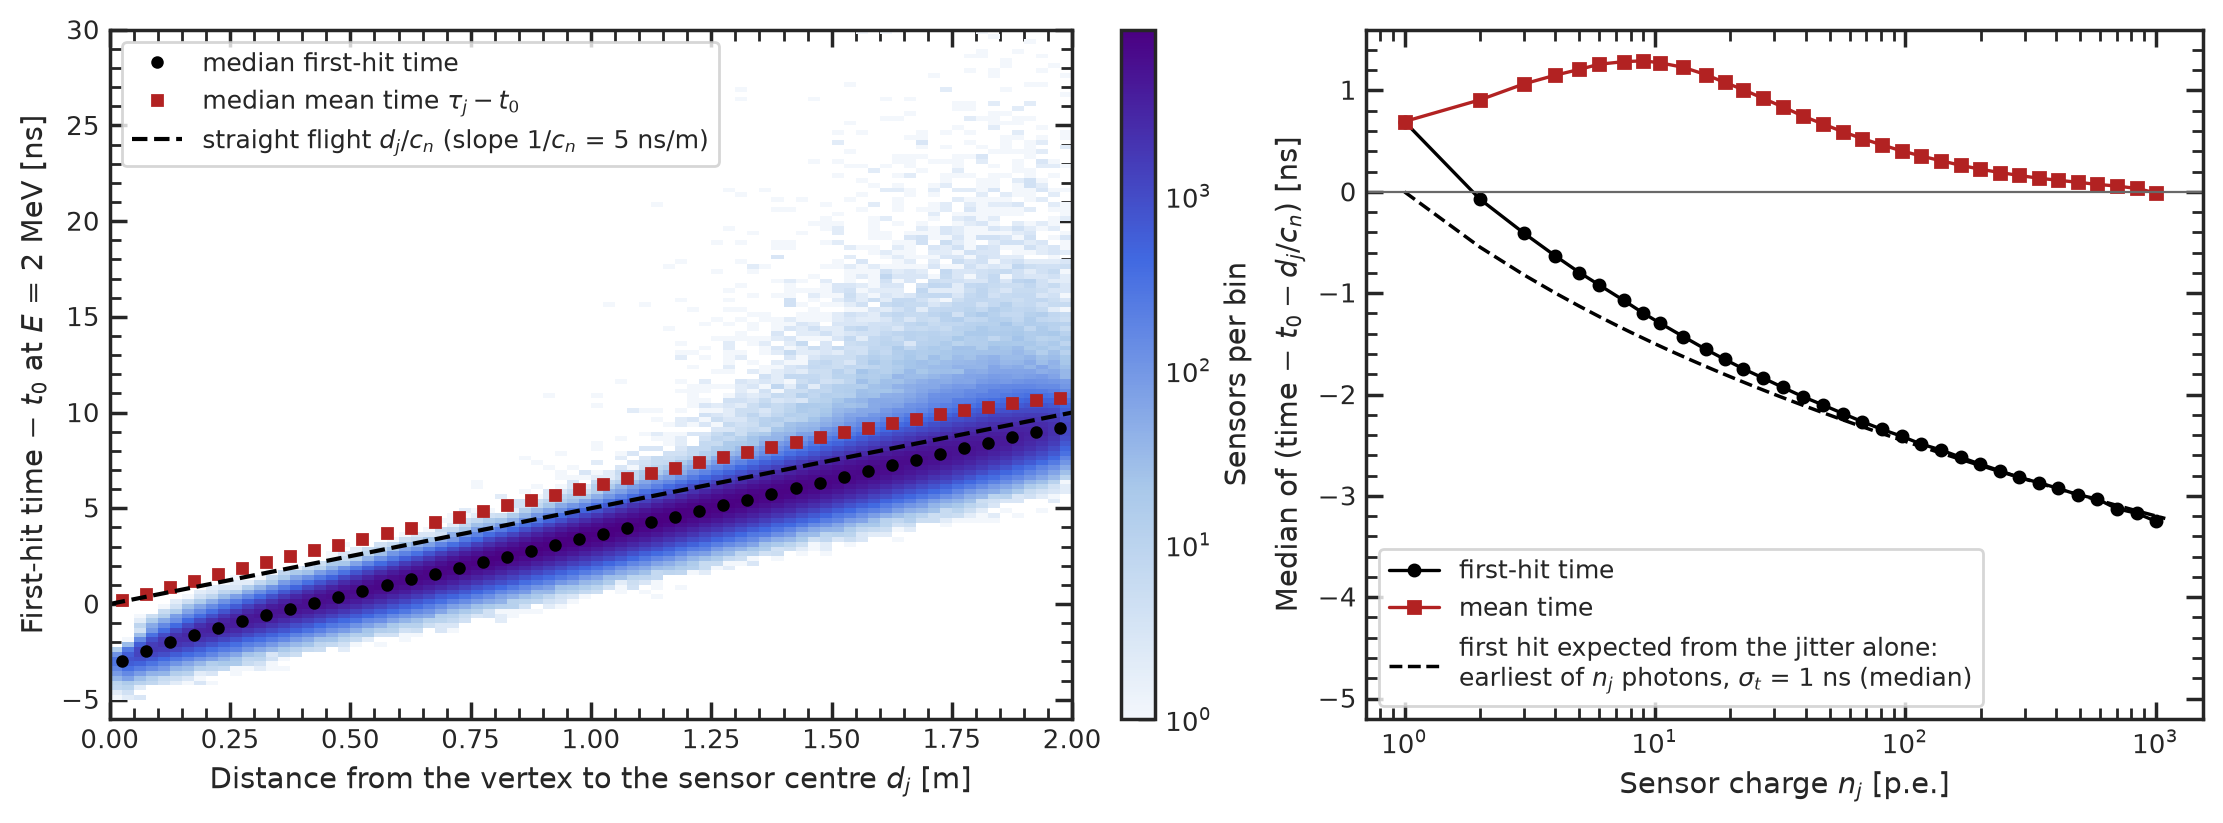

In [11]:
show("t2_5_first_hit_time")

### 2. First-hit time versus distance

The median first-hit time rises with d_j, but a straight-line fit (0.3-1.8 m)
gives 5.98 ns/m and -2.47 ns instead of 1/c_n = 5 ns/m through zero, and 94.0 % of the first hits arrive before
t0 + d_j/c_n. The first hit is the earliest of n_j jittered photons, and its offset follows the expectation for
1 ns jitter alone (median of the minimum of n Gaussians: -1.50, -2.46, -2.83 ns for n = 10, 100, 300; measured -1.30,
-2.41, -2.82 ns); since the near sensors are the bright ones, the offset changes with d and steepens the slope. The
mean time has the opposite bias (+0.2 to +1.3 ns, late light): timing does carry the vertex, but entangled with the
charge.

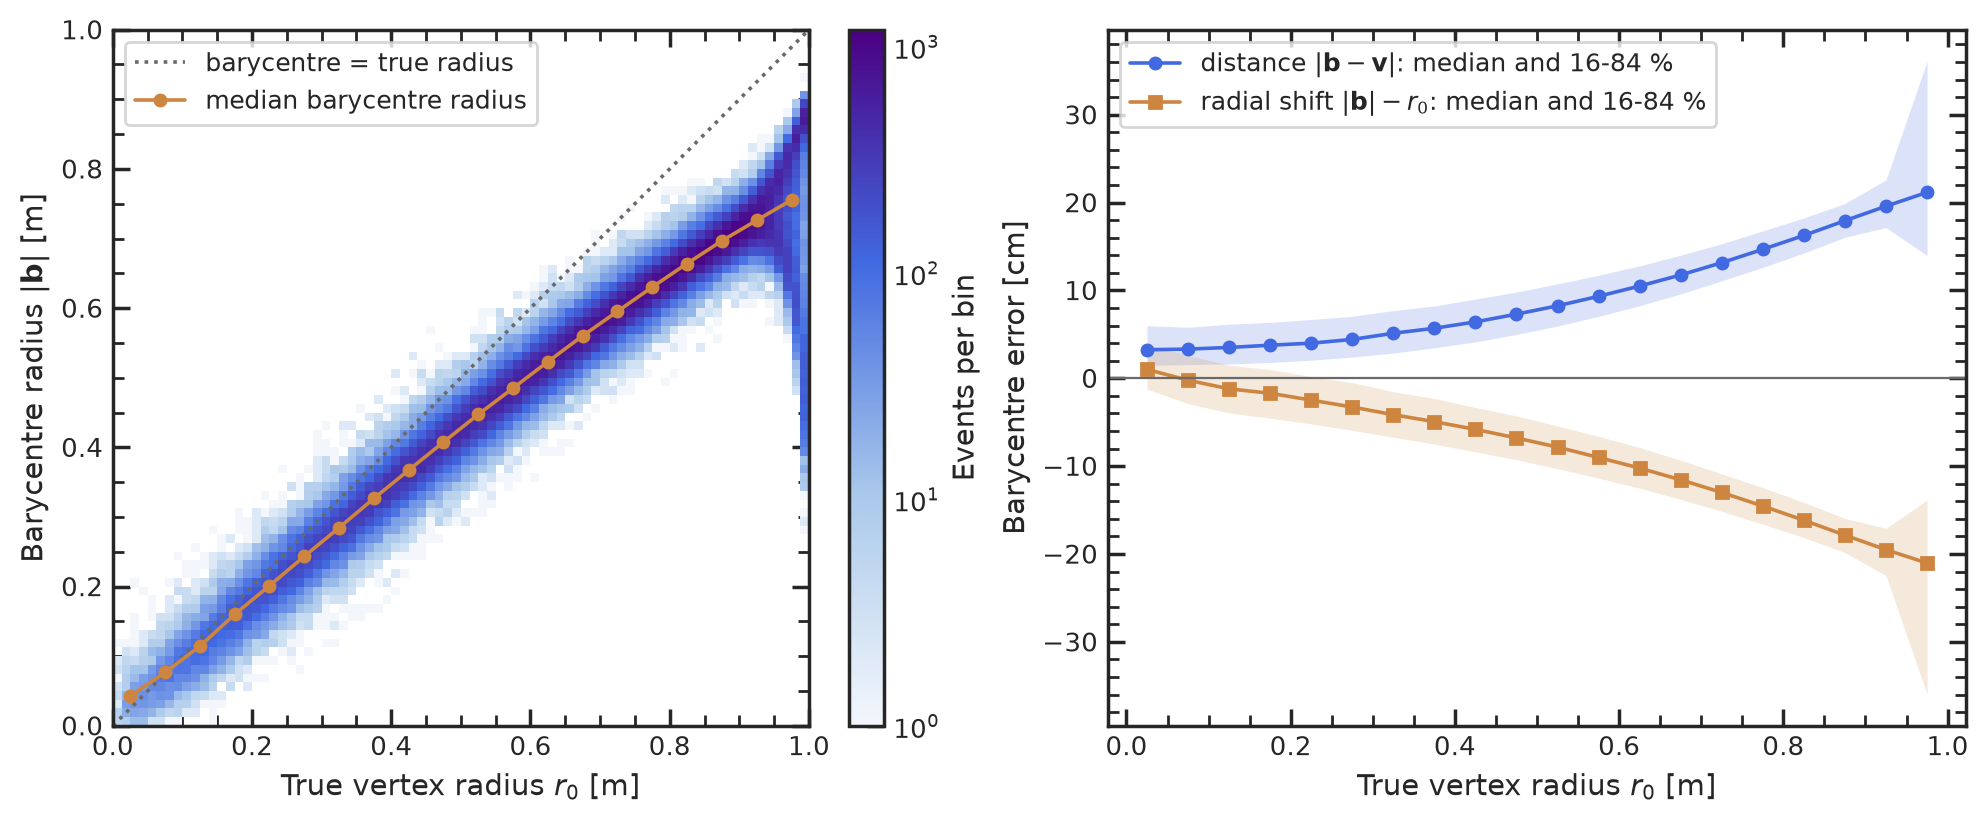

In [12]:
show("t2_5_barycentre")

### 3. Barycentre

The charge-weighted mean of the sensor positions has a median error of 3.3 cm at the centre
(r < 0.1 m), 12.7 cm over the disc and 21.2 cm next to the wall (r > 0.95 m), and it is pulled inwards: |b|/r falls
from 0.97 (0.05 < r < 0.1 m) to 0.78 in the last bin, a radial shift of -21 cm, and |b| never exceeds 0.93 m. The
direction is good (median azimuth error 1.3° for r > 0.3 m), but the charge pattern is too smooth for a weighted mean:
even the far side of the ring collects light and pulls the estimate towards the centre.

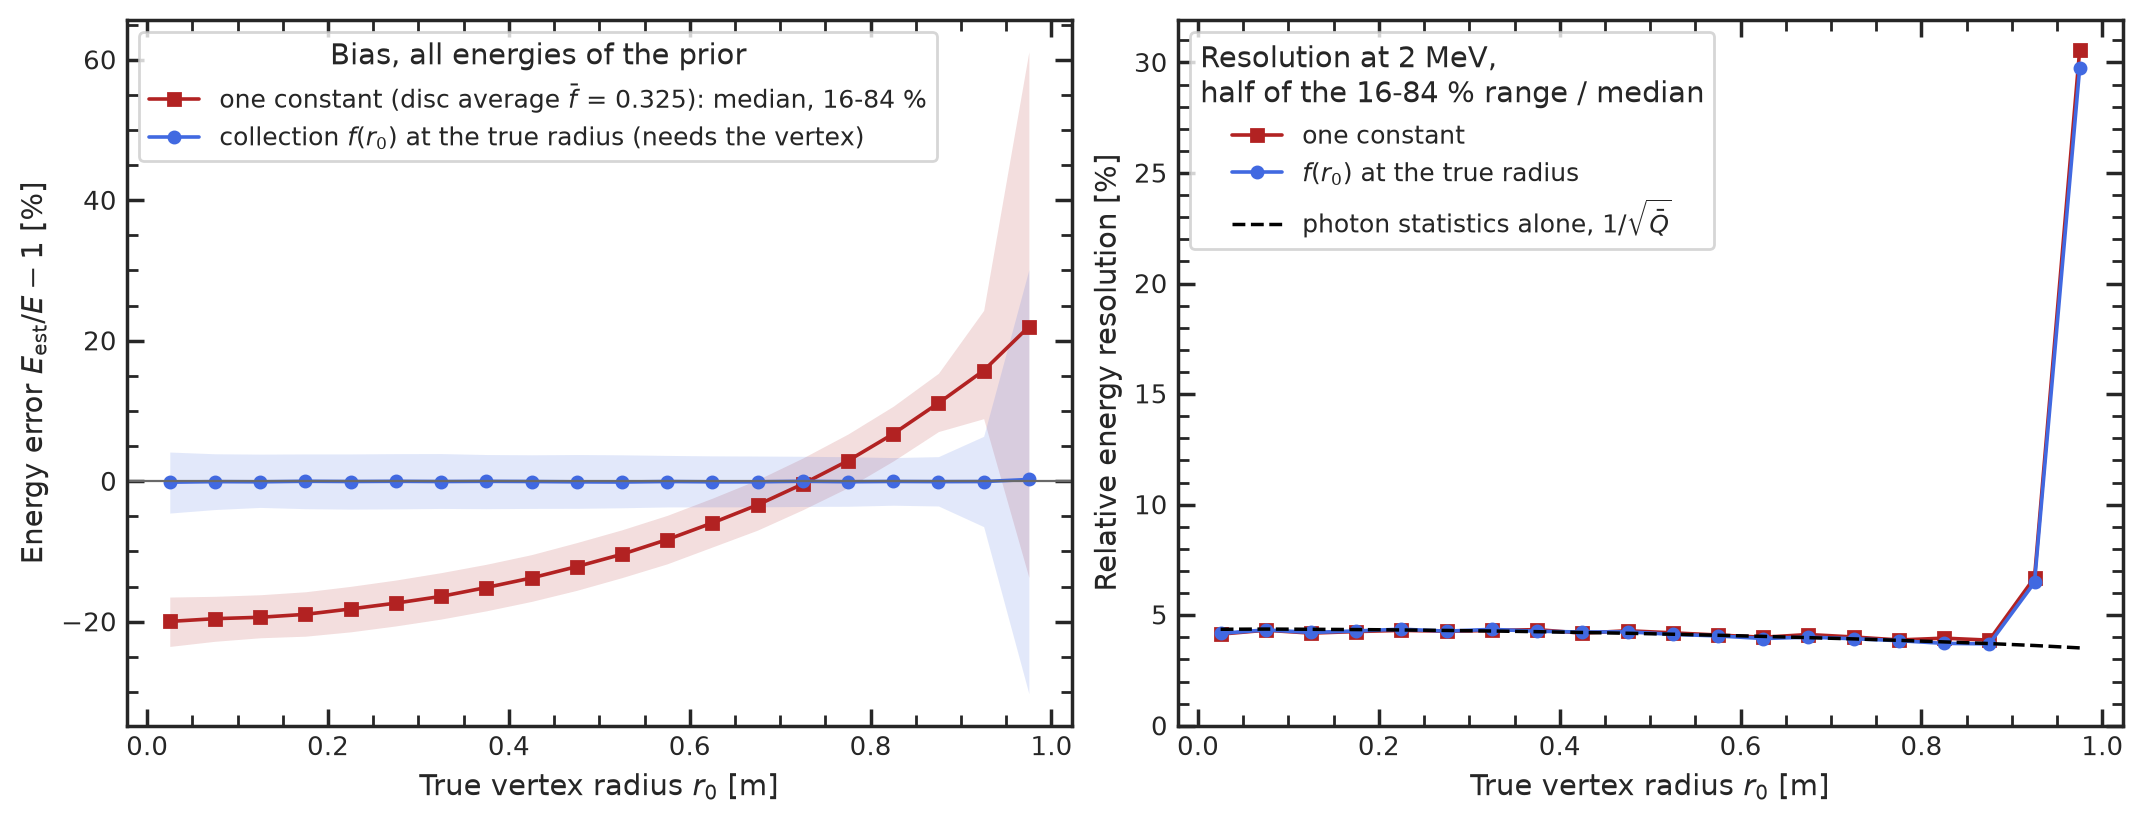

In [13]:
show("t2_5_naive_energy")

### 4. Naive energy

With one constant, the disc average f̄ = 0.3254, E = Q/(Y f̄) is biased by -20.0 % at the centre
and +22.0 % at the wall, crossing zero at r ≈ 0.73 m; over the whole prior its 16-84 % half-width is 14.1 %, against
4.5 % if the collection f(r) at the true radius is used and a photon-statistics median of 3.4 %. At a fixed 2 MeV the
resolution equals the photon statistics 1/sqrt(Q) (4.1-4.4 % falling to 3.9 %) up to r = 0.9 m, but jumps to 6.7 % and
30.6 % in the last two bins, and knowing r exactly does not cure it (6.5 %, 29.8 %): near the wall the collection
depends on the vertex in two dimensions (item 8). T3.4 repeats this estimator for every preset with the measures of
the TASKS.md hint (k = median of Q/E, median bias, central 68 % interval) and with 1 cm bins in the last 10 cm; its
wall bias for the full model is larger than the +22.0 % quoted here for r > 0.95 m, because the last centimetre alone
is more extreme than the whole last 5 cm (see answers/T3.4.md for the numbers).

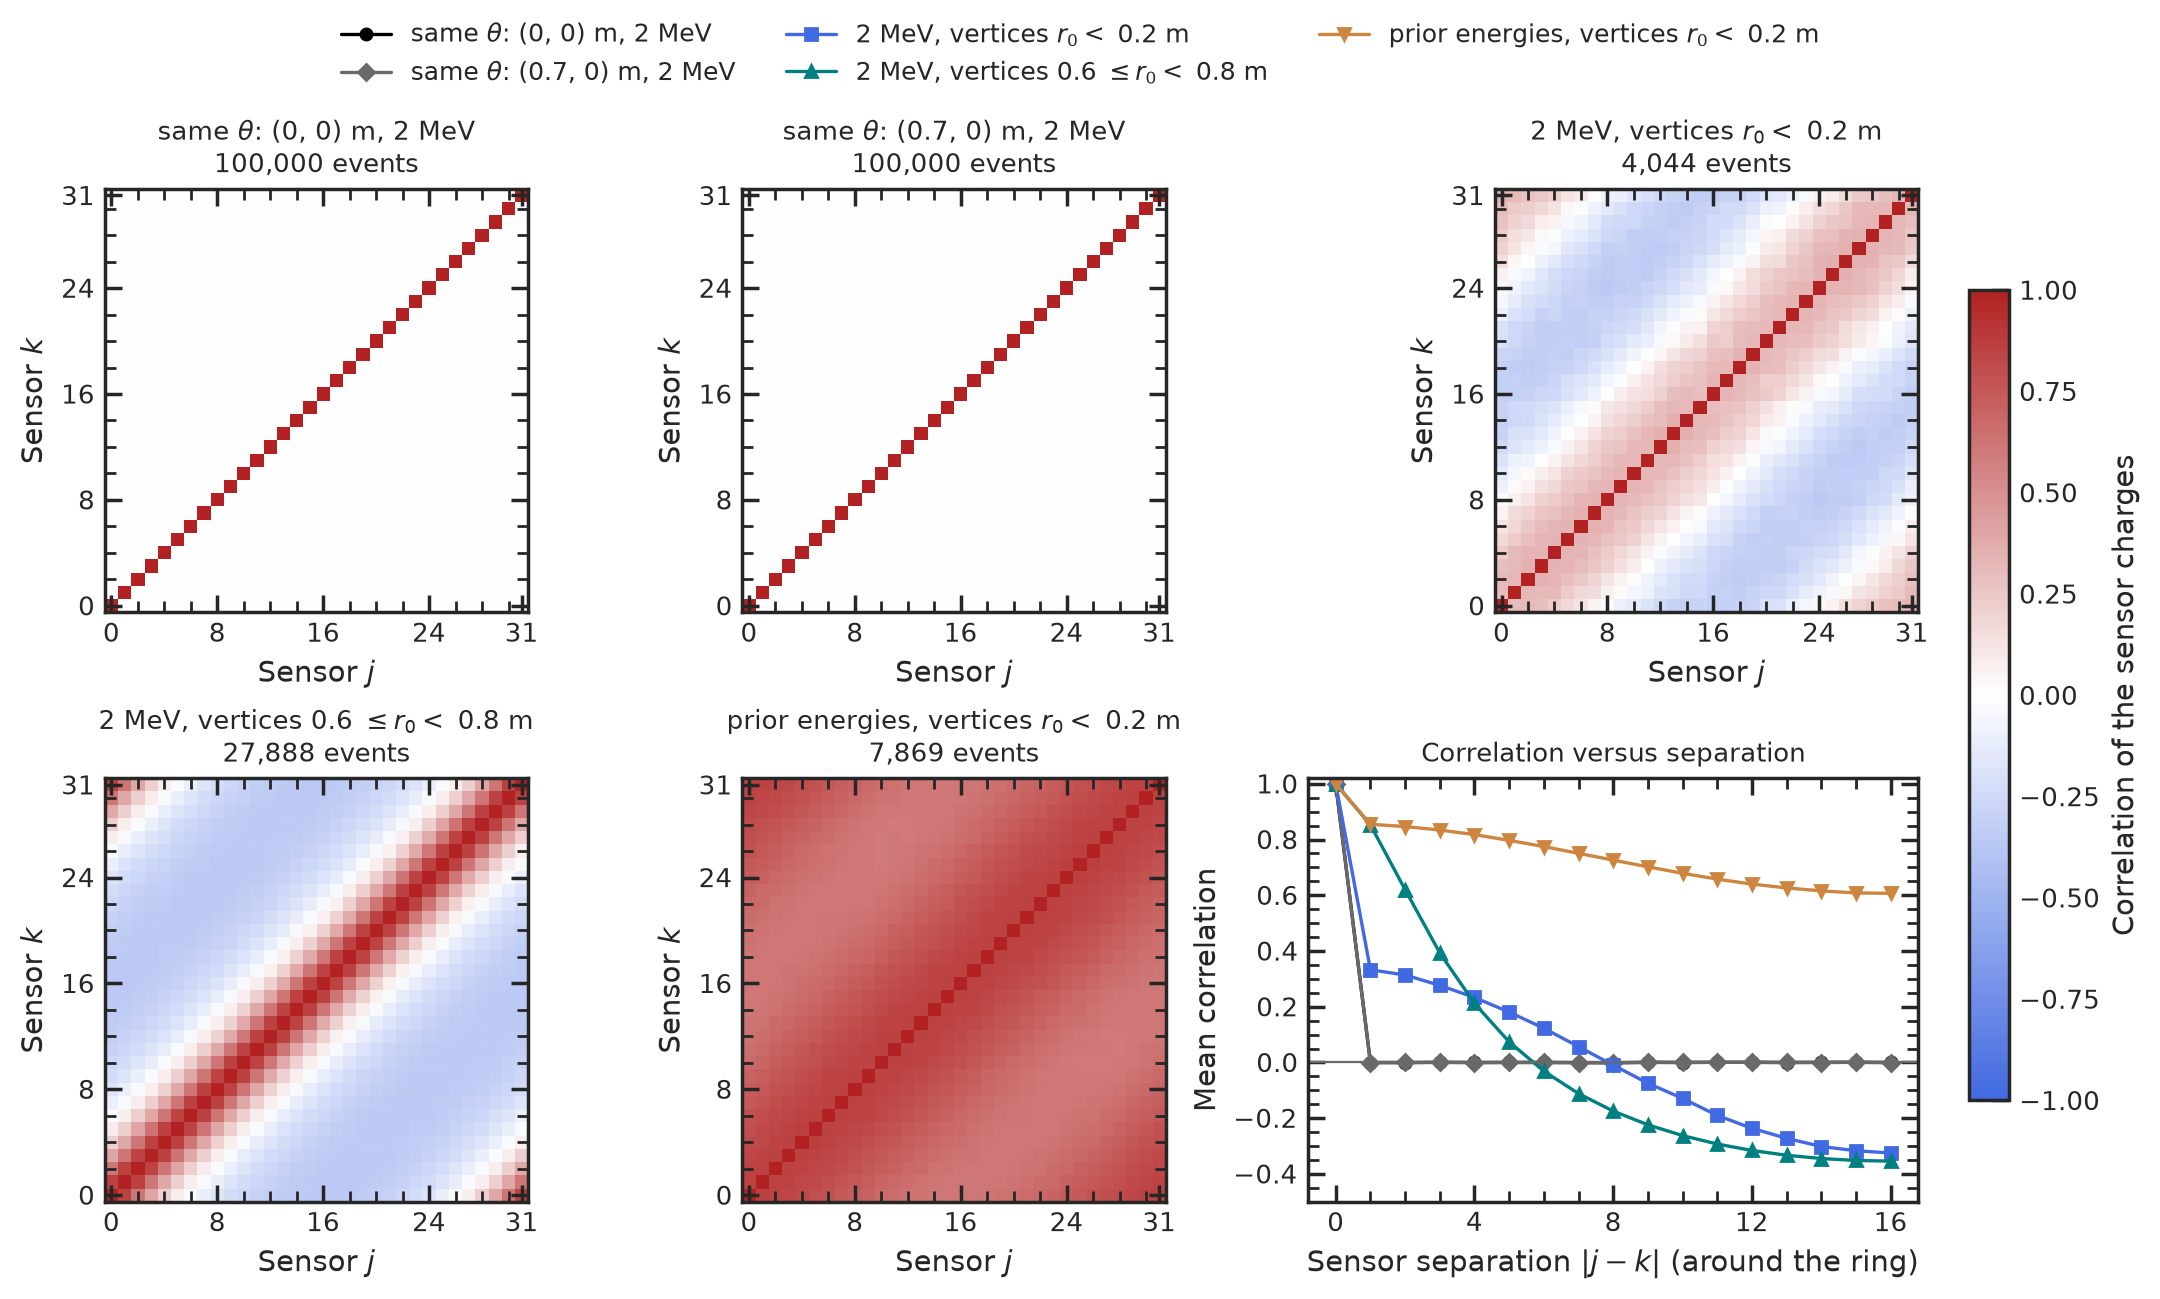

In [14]:
show("t2_5_correlations")

### 5. Correlations

For the same θ simulated 100 000 times (at the centre or at (0.7, 0) m) the sensors are
uncorrelated: mean off-diagonal correlation 0.0000 and -0.0001, largest |value| 0.012 and 0.010, which is what pure
noise gives for 496 pairs (r √N = 3.7 and 3.1; shuffled samples give a median of 3.2, permutation p = 0.10 and 0.72),
and every sensor has variance/mean = 0.99-1.01. With Poisson photon numbers every sensor charge is an independent
Poisson variable (Poisson thinning), so the likelihood factorises given θ. Correlations appear only when
θ varies: at 2 MeV with vertices r < 0.2 m neighbours correlate at +0.33 and opposite sensors at -0.33 (a dipole:
moving towards one side brightens it and dims the other), for 0.6 ≤ r < 0.8 m at +0.85 and -0.35, and with the prior
energies (r < 0.2 m) everything is positive (+0.61 to +0.85) because all sensors scale with E.

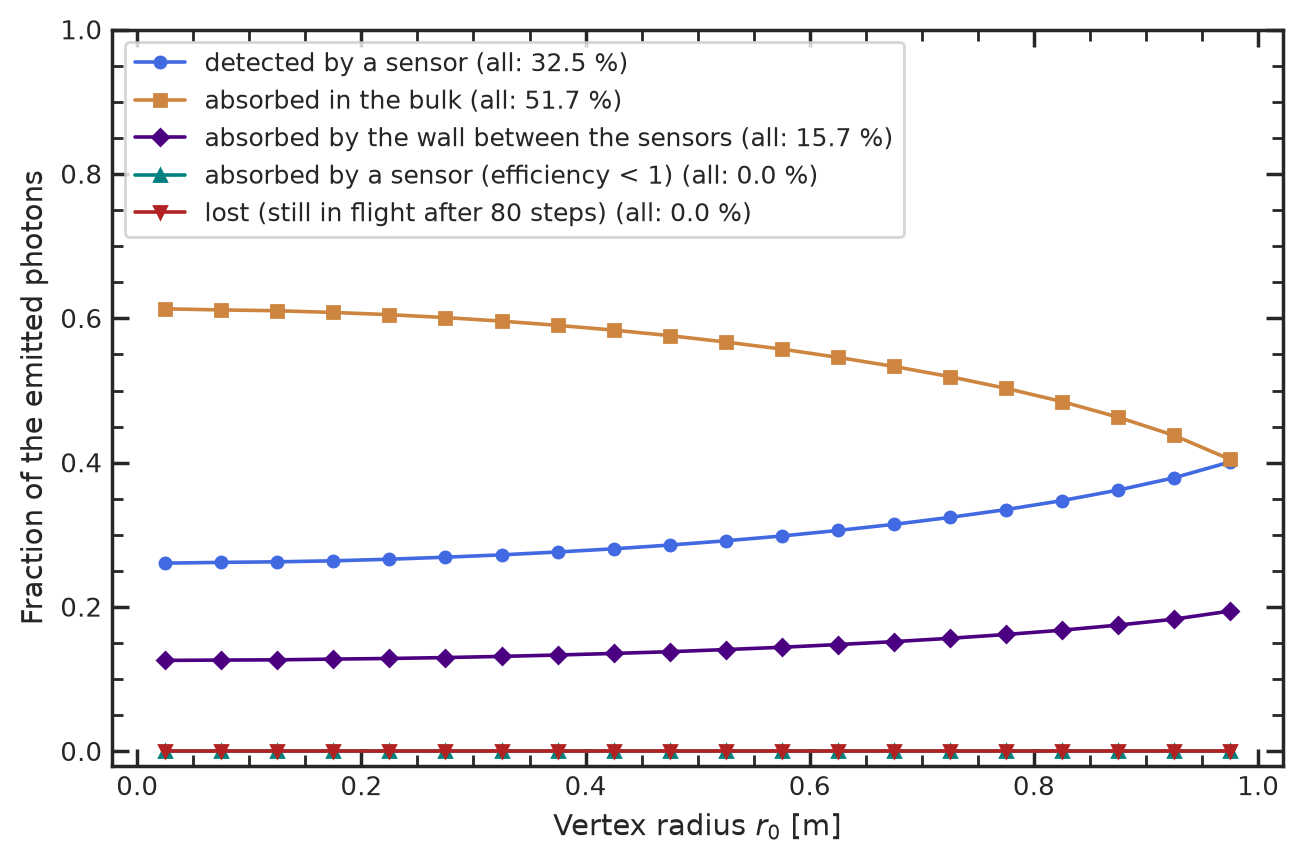

In [15]:
show("t2_5_photon_fates")

### 6. Photon fates

Over the disc 32.5 % of the photons are detected, 51.7 % are absorbed in the bulk, 15.7 % by the
bare wall, none by the sensors (efficiency 1) and none is lost (the 80-step limit is never reached). From the centre to
the wall bin the bulk absorption drops from 61.3 % to 40.5 % (shorter paths), while detection rises from 26.1 % to
40.1 % and wall absorption from 12.6 % to 19.4 %: more light reaches the wall when the vertex is close to it.

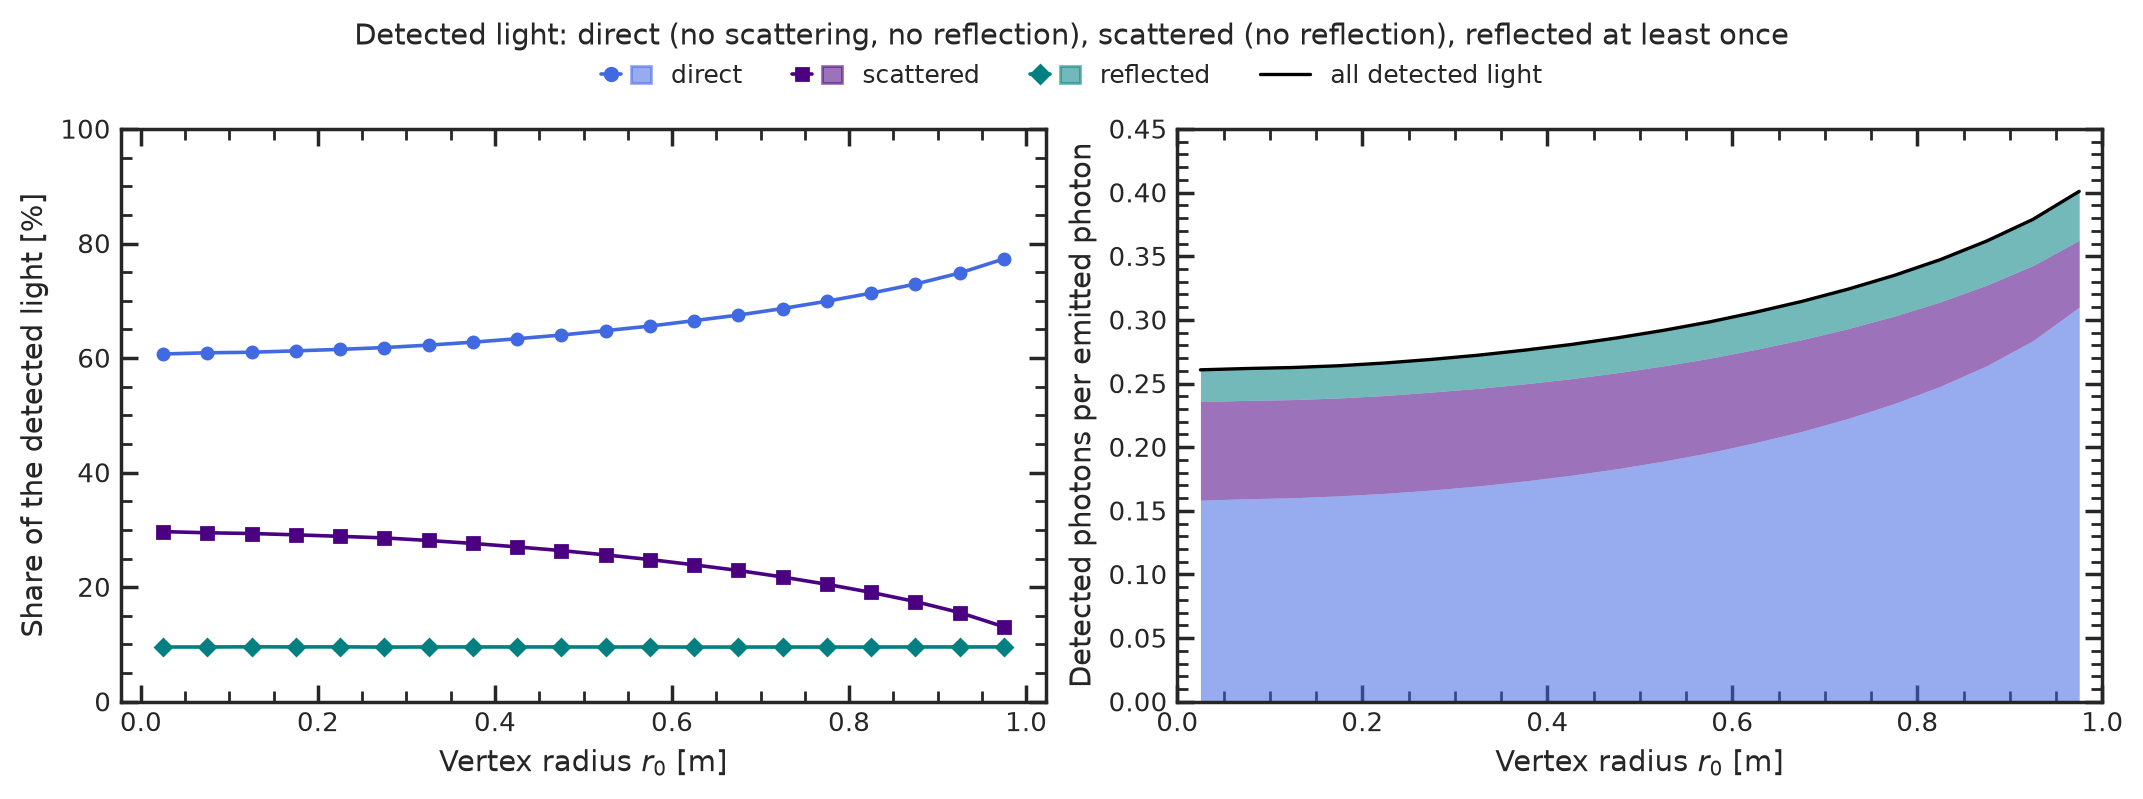

In [16]:
show("t2_5_composition")

### 7. Composition

The direct share of the detected light is 60.8 % for vertices exactly at the centre, 69.3 %
averaged over the disc and 77.3 % in the wall bin; the scattered share falls from 29.7 % to 21.1 % and 13.1 %, and the
reflected share stays at 9.6 % everywhere (the seminar's "69 / 21 / 10 %" is the disc average, not the centre). A
plausible reason for the constant reflected share: a reflected photon restarts at the wall wherever it came from, and
on average the light reaching the wall meets sensors and bare wall in the ratio of the photocoverage. Per emitted
photon the rise of the collection from 0.26 to 0.40 is carried by the direct light (0.158 to 0.310), while the
scattered light even decreases (0.077 to 0.052).

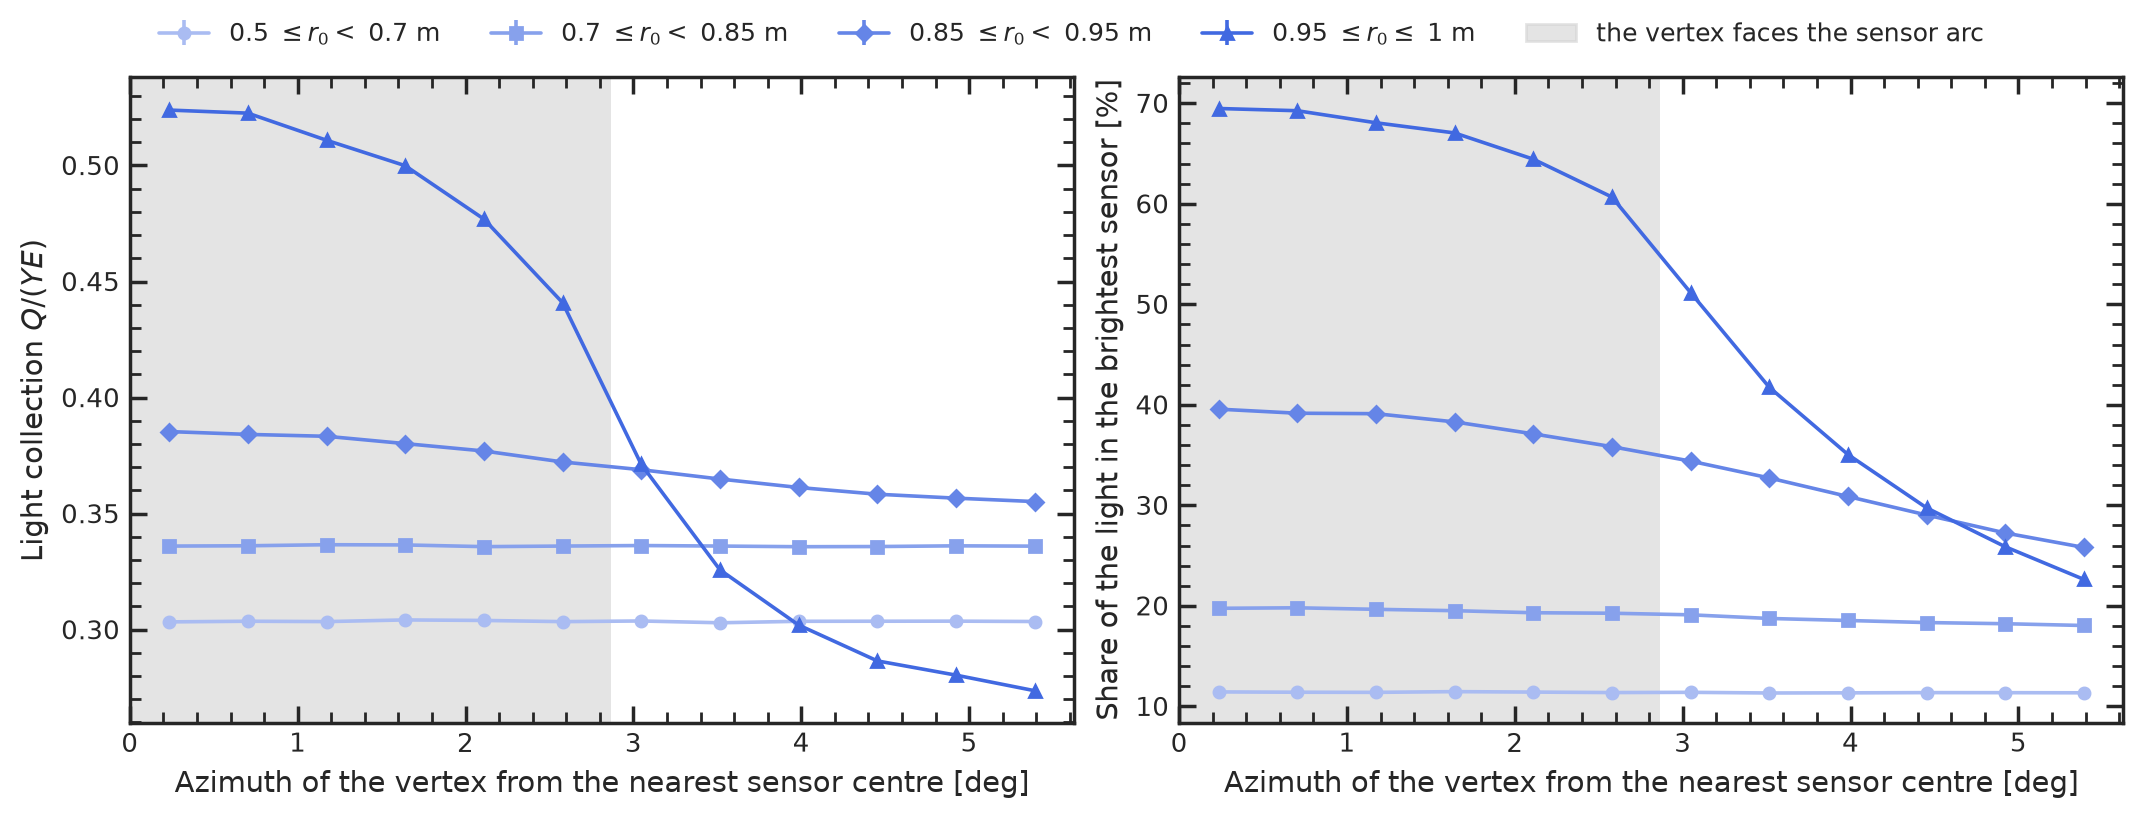

In [17]:
show("t2_5_azimuthal_modulation")

### 8. Azimuthal modulation (own)

For r ≥ 0.95 m the light collection is 0.524 when the vertex faces a sensor centre
and 0.274 when it faces the middle of a gap (a factor 1.9), and the brightest sensor holds 69 % versus 23 % of the
light; at 0.85-0.95 m the effect is 0.385 versus 0.355, and below 0.85 m it is gone (0.336 versus 0.336). Near the
wall the response is therefore a function of (x0, y0), not of r alone: no radial calibration is enough, and the
network needs the full charge pattern, which tells which sensor is nearest and how much light it got.

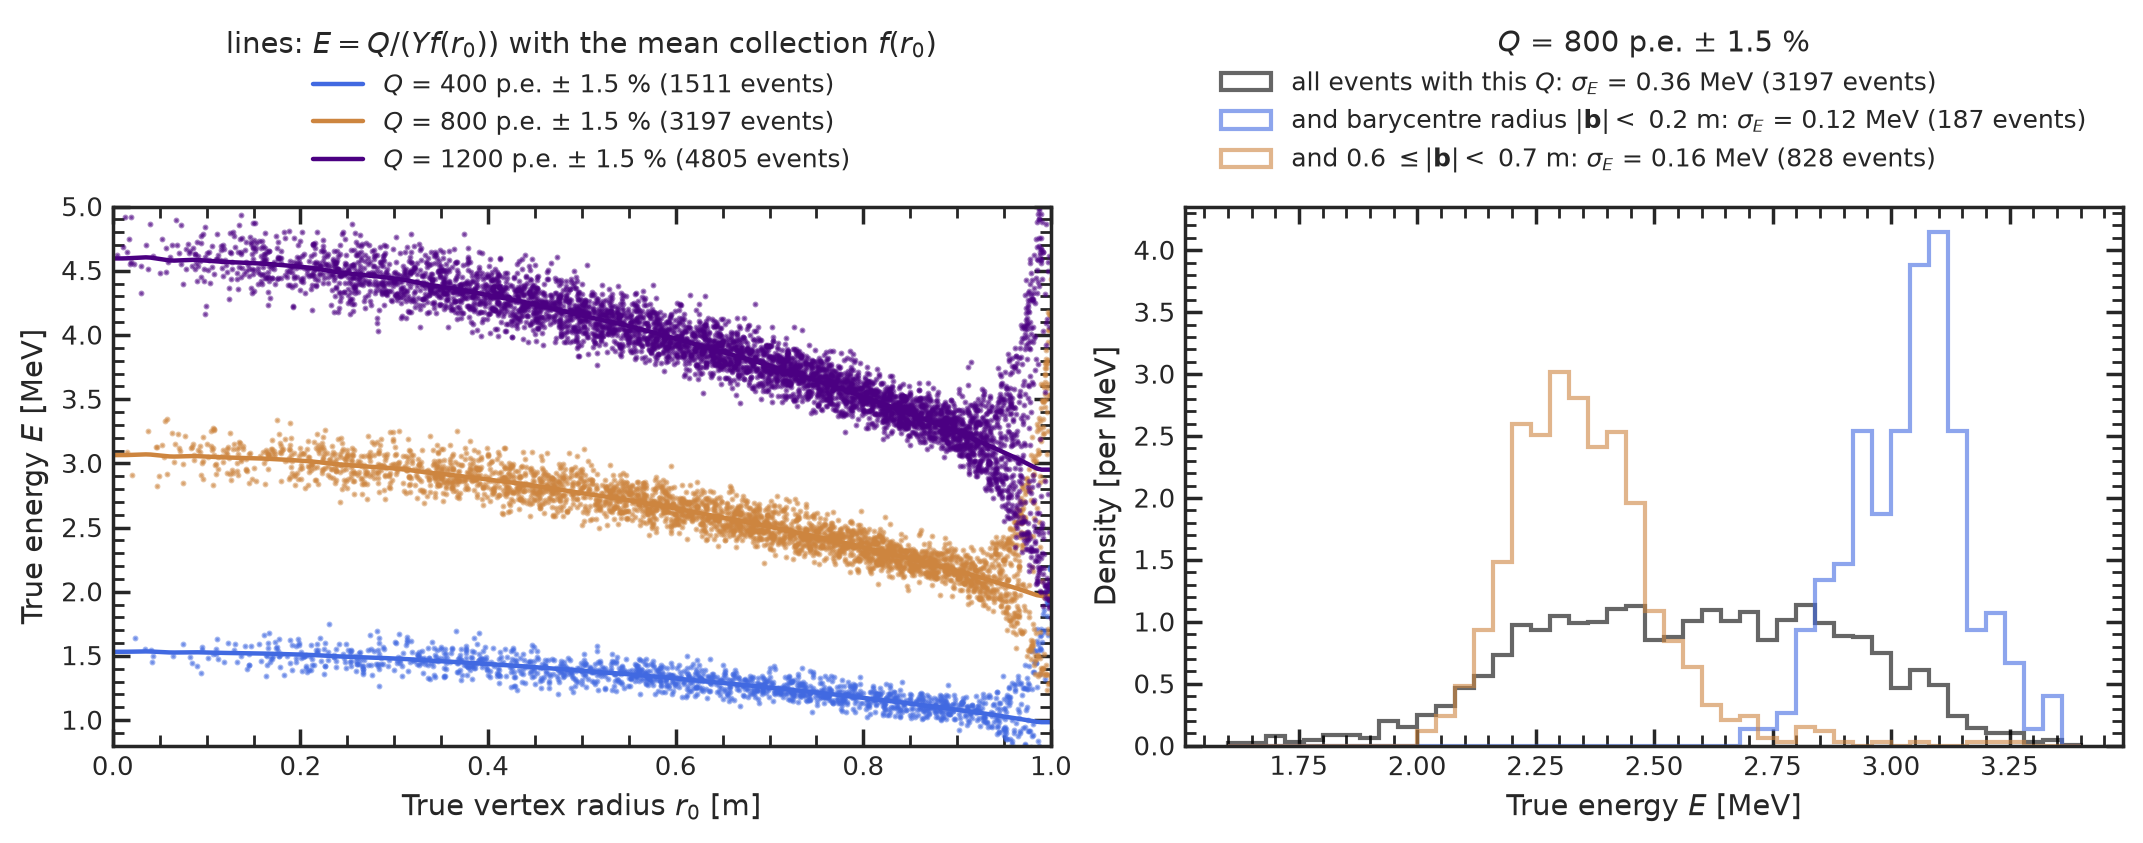

In [18]:
show("t2_5_energy_radius_degeneracy")

### 9. Energy-radius degeneracy (own)

Events with the same Q lie on the ridge E = Q/(Y f(r)): for Q = 800 ± 1.5 %
p.e. the true energies span 2.23-2.92 MeV (16-84 %, σ_E = 0.36 MeV; the ridge runs from 1.97 to 3.07 MeV). Adding
one pattern feature narrows it: with a barycentre radius |b| < 0.2 m the energy is 3.04 ± 0.12 MeV, with
0.6 ≤ |b| < 0.7 m it is 2.35 ± 0.16 MeV. This is the job of the posterior estimator: use the pattern to find the
point on the ridge; the selection itself is a crude posterior estimate (rejection ABC), as in T1.2.

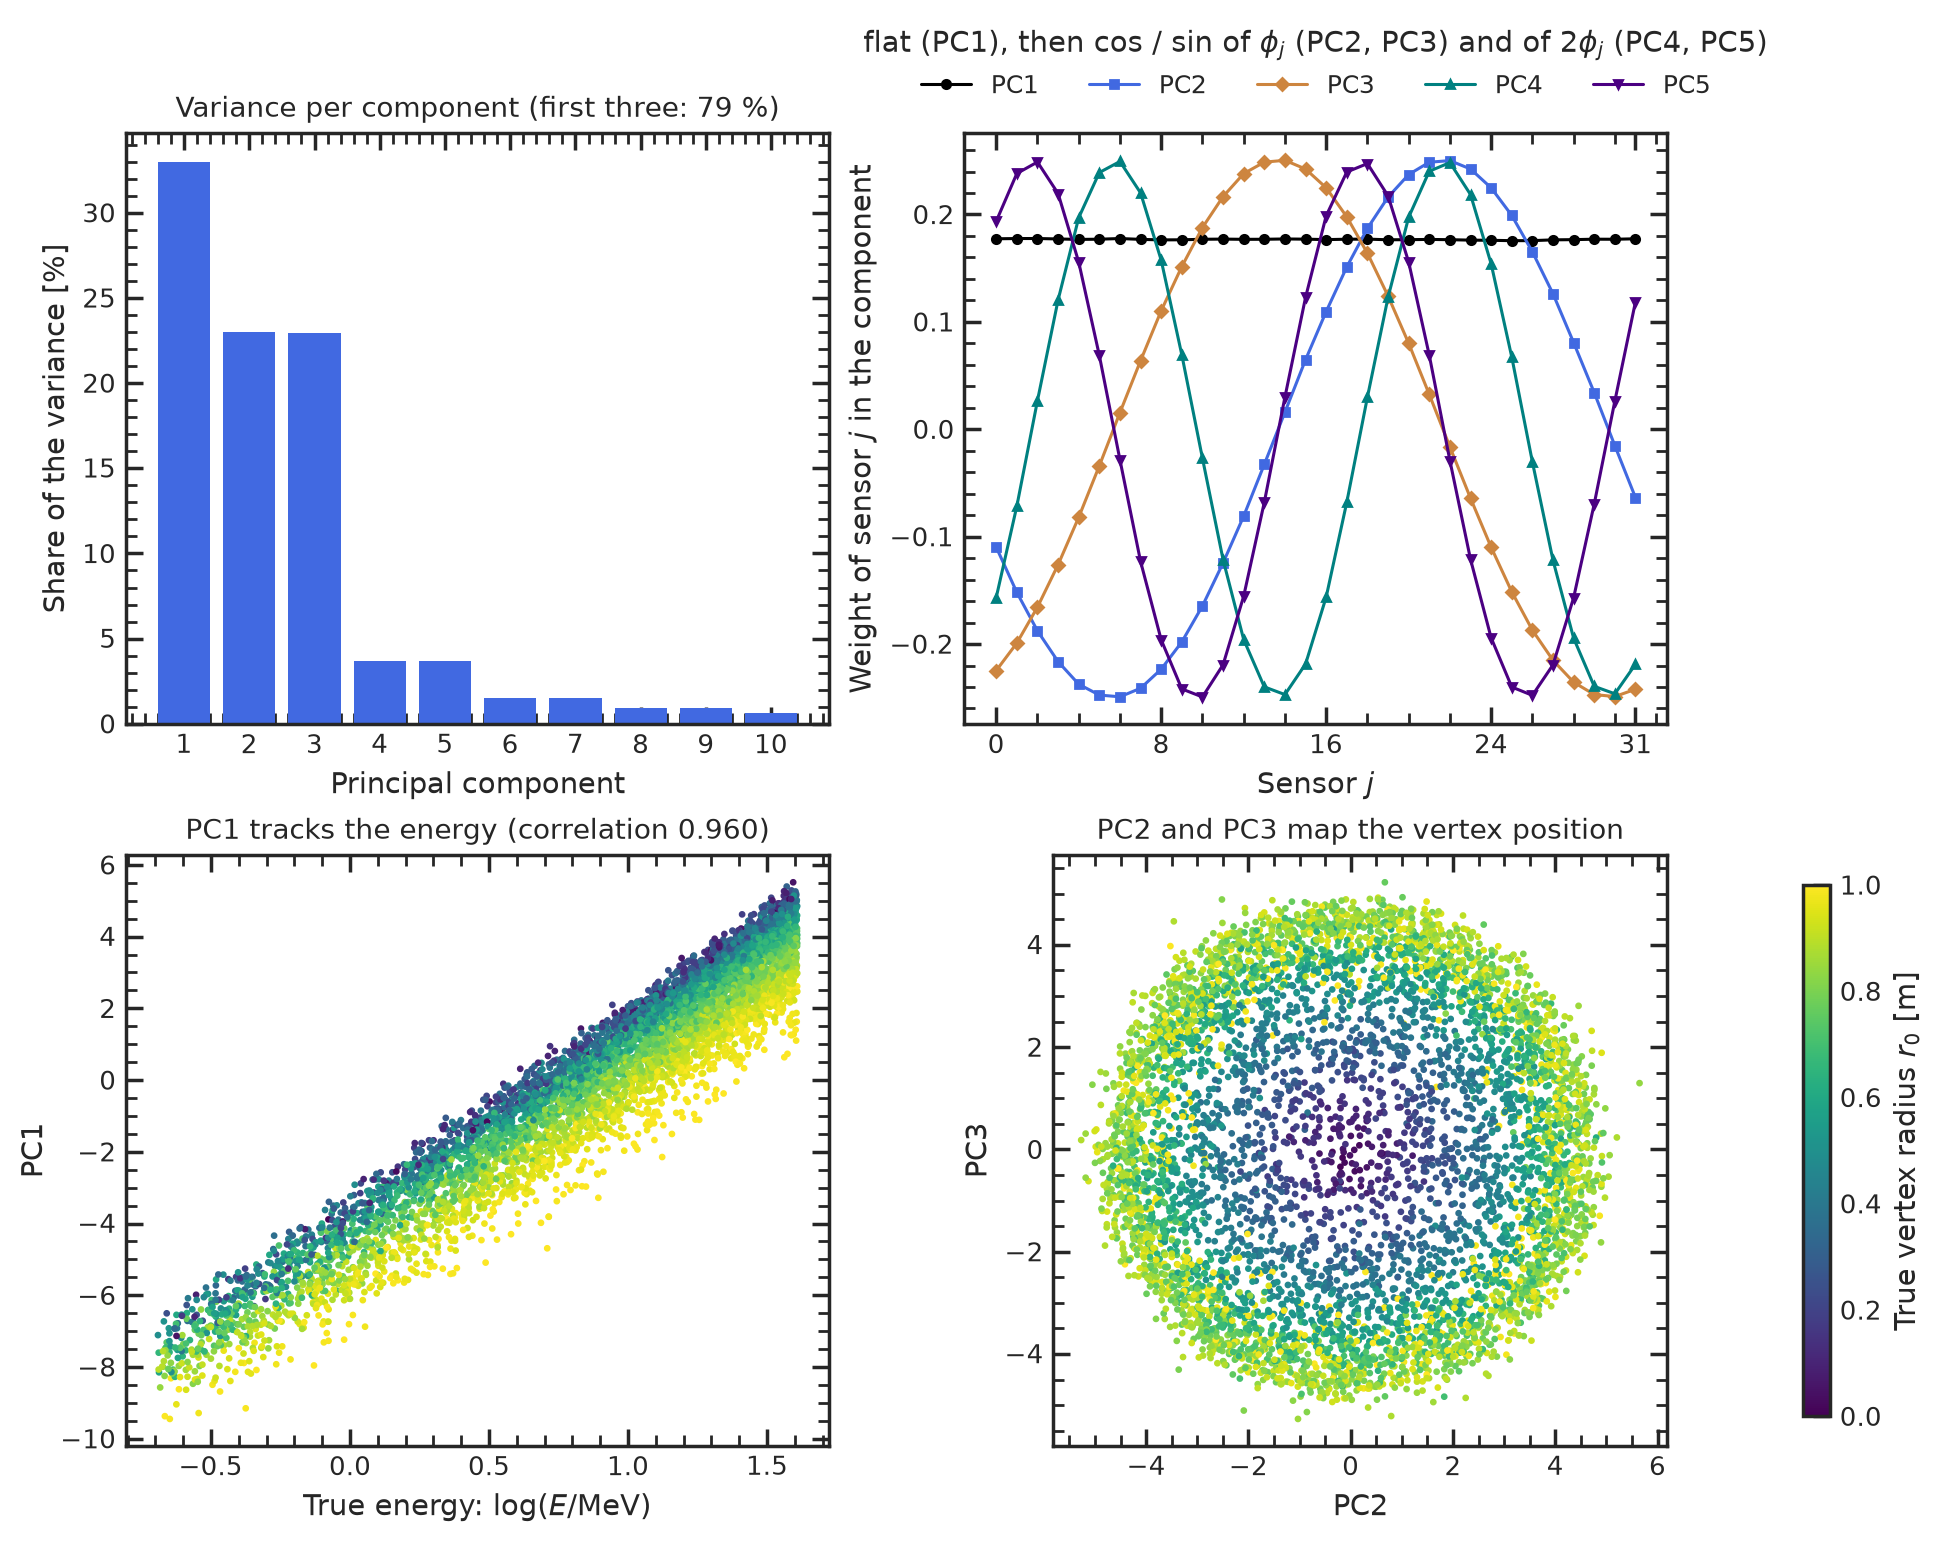

In [19]:
show("t2_5_pca_network_input")

### 10. Principal components (own)

The 32 log charges are dominated by a few directions: PC1 (33.0 % of the variance)
has flat weights and correlates with log E at 0.960; PC2 and PC3 (23.0 % and 22.9 %) are the cosine and sine of the
sensor angle and map the vertex: the angle of (PC2, PC3) reproduces the true azimuth up to a rotation and mirror
(agreement 0.993) and its length correlates with r at 0.864; PC4 and PC5 (3.7 % each) are the cos 2φ / sin 2φ
patterns. Because the detector is rotationally symmetric the covariance of the sensors depends only on their
separation, so the components are Fourier modes of the ring. The first three components already hold 78.9 % of the
variance, so the input "knows" E and the vertex almost linearly; what the network must learn are the non-linear parts,
e.g. PC1 also depends on r (correlation -0.245: near-wall events concentrate their light and have a lower mean log
charge).

*Script:* `task2_proposals.py` (200 000 prior events, 100 000 events at E = 2 MeV, and 100 000 events each with the same θ at (0, 0) m and at (0.7, 0) m, 2 MeV). *Numbers:* `results/T2.json` under `T2.5`.